<a href="https://colab.research.google.com/github/scao1828/main/blob/main/ForestHillsStadiumConcerts.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import os
import requests
from tqdm import tqdm

# Correct public CloudFront CDN URLs for NYC TLC data
TLC_BASE_URL = "https://d37ci6vzurychx.cloudfront.net/trip-data/"
TAXI_LOOKUP_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zone_lookup.csv"

files_to_download = {
    "taxi_zone_lookup.csv": TAXI_LOOKUP_URL,
    "fhvhv_tripdata_2026-06.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-06.parquet",
    "fhvhv_tripdata_2026-07.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-07.parquet",
    "fhvhv_tripdata_2026-08.parquet": f"{TLC_BASE_URL}fhvhv_tripdata_2026-08.parquet"
}

def download_file(url, destination):
    if os.path.exists(destination):
        print(f"{destination} already exists. Skipping.")
        return

    print(f"Downloading {destination} from {url}...")
    # Include standard User-Agent header to avoid 403 Forbidden/Access Denied errors
    headers = {
        "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/115.0.0.0 Safari/537.36"
    }
    response = requests.get(url, headers=headers, stream=True)
    response.raise_for_status()

    total_size = int(response.headers.get('content-length', 0))
    block_size = 1024 * 1024  # 1 MB

    with open(destination, 'wb') as file, tqdm(
        desc=destination,
        total=total_size,
        unit='iB',
        unit_scale=True,
        unit_divisor=1024,
    ) as bar:
        for data in response.iter_content(block_size):
            size = file.write(data)
            bar.update(size)
    print(f"Finished downloading {destination}\n")

for filename, url in files_to_download.items():
    try:
        download_file(url, filename)
    except Exception as e:
        print(f"Error downloading {filename}: {e}")

taxi_zone_lookup.csv: 12.0kiB [00:00, 4.94MiB/s]

Finished downloading taxi_zone_lookup.csv




fhvhv_tripdata_2026-06.parquet: 100%|██████████| 483M/483M [00:05<00:00, 92.9MiB/s]


Finished downloading fhvhv_tripdata_2026-06.parquet



fhvhv_tripdata_2026-07.parquet: 100%|██████████| 487M/487M [00:02<00:00, 222MiB/s]


Finished downloading fhvhv_tripdata_2026-07.parquet



fhvhv_tripdata_2026-08.parquet: 100%|██████████| 479M/479M [00:02<00:00, 226MiB/s]

Finished downloading fhvhv_tripdata_2026-08.parquet



Processing June 2026 parquet file...
Processing July 2026 parquet file...
Processing August 2026 parquet file...

--- Top Inbound Origins (Average per Concert Day) ---
     Neighborhood  total_trips  avg_per_concert_day
     Forest Hills         4588               229.40
        Rego Park         1521                76.05
         Elmhurst          849                42.45
      Kew Gardens          832                41.60
         Flushing          689                34.45
   Middle Village          677                33.85
         Glendale          613                30.65
        Ridgewood          592                29.60
    Richmond Hill          575                28.75
Kew Gardens Hills          561                28.05

--- Top Outbound Destinations (Average per Concert Day) ---
           Neighborhood  total_trips  avg_per_concert_day
         Outside of NYC         1543                77.15
           Forest Hills         1371                68.55
          Richmond Hill  

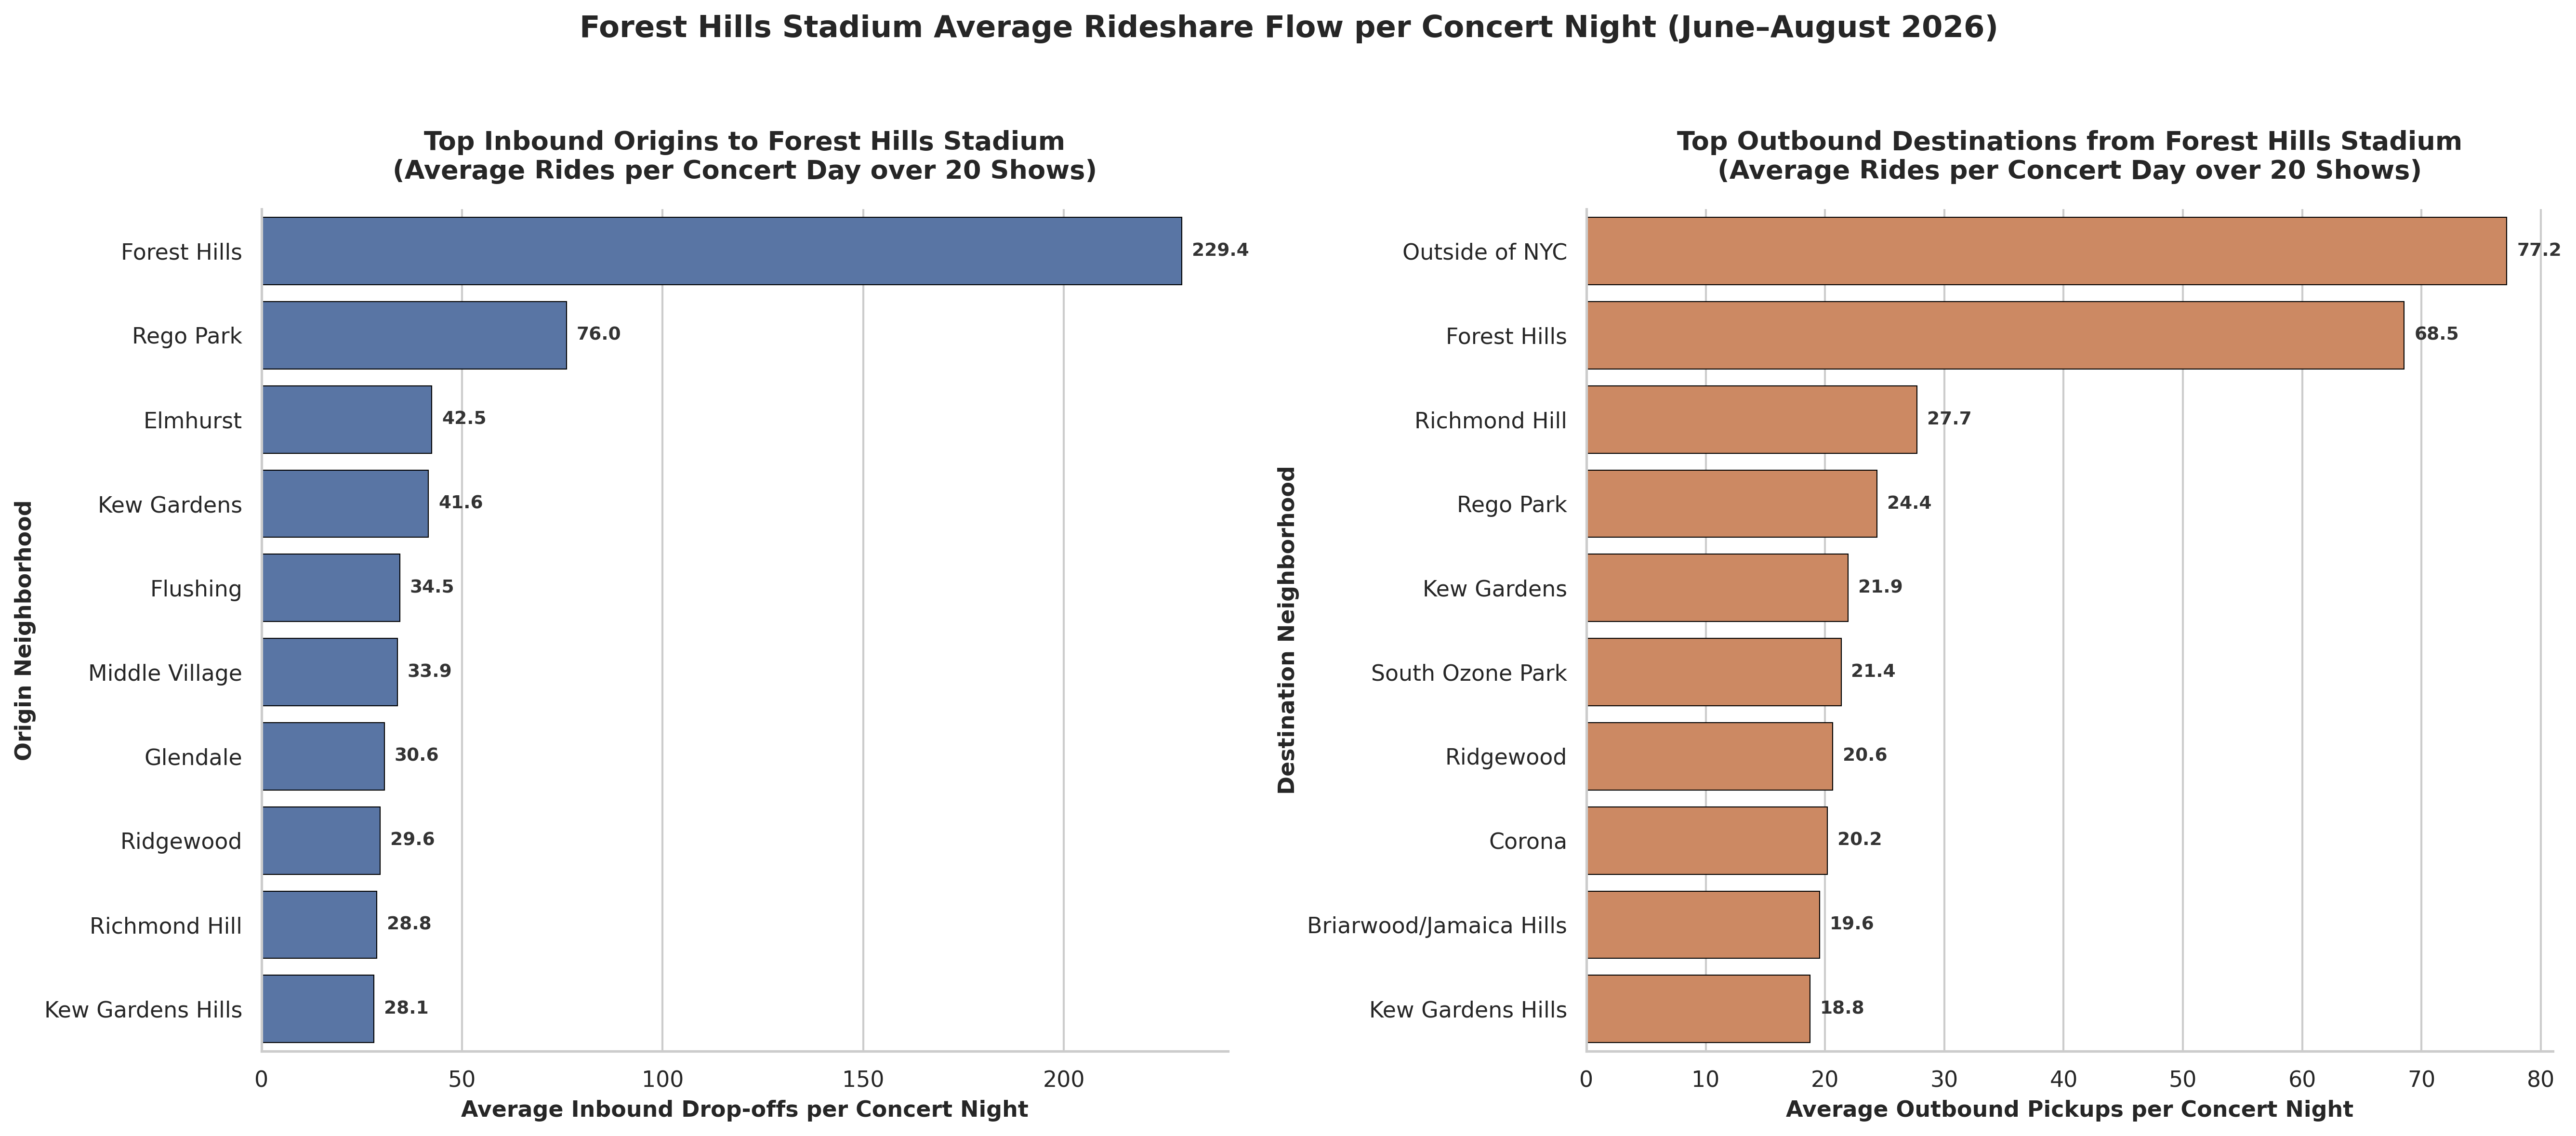


Success! Average per concert day visualization saved to 'forest_hills_2026_avg_per_concert_day.png'.


In [6]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
TAXI_ZONE_LOOKUP_PATH = "taxi_zone_lookup.csv"

FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium (Total = 20 concert days)
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
num_concert_days = len(concert_set)

VENUE_ZONE_ID = 95  # Forest Hills Taxi Zone ID

if not os.path.exists(TAXI_ZONE_LOOKUP_PATH):
    raise FileNotFoundError(f"'{TAXI_ZONE_LOOKUP_PATH}' not found in Colab workspace.")

# ==========================================
# 2. DATA PROCESSING FOR CONCERT DAYS ONLY
# ==========================================
inbound_concert_list = []
outbound_concert_list = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 parquet file...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID']
    df = pd.read_parquet(file_path, columns=columns)

    # Parse timestamps
    dt = pd.to_datetime(df['pickup_datetime'])
    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])

    # Adjust event date for post-midnight trips (hours 0-3 belong to previous night's event)
    event_dates = dt.dt.date.copy()
    early_morning_mask = dt.dt.hour < 4
    event_dates[early_morning_mask] = (dt[early_morning_mask] - pd.Timedelta(days=1)).dt.date
    df['event_date_str'] = event_dates.astype(str)

    # Filter strictly for official concert event dates
    is_concert_event = df['event_date_str'].isin(concert_set)

    # Robust numeric time window filters
    dropoff_hour = dropoff_dt.dt.hour
    dropoff_minute = dropoff_dt.dt.minute
    inbound_mask = (df['DOLocationID'] == VENUE_ZONE_ID) & (
        ((dropoff_hour >= 17) & (dropoff_hour < 20)) |
        ((dropoff_hour == 20) & (dropoff_minute <= 30))
    )

    pickup_hour = dt.dt.hour
    pickup_minute = dt.dt.minute
    outbound_mask = (df['PULocationID'] == VENUE_ZONE_ID) & (
        ((pickup_hour >= 22) & (pickup_hour <= 23)) |
        ((pickup_hour == 0) & (pickup_minute <= 30))
    )

    inbound_concert_list.append(df[is_concert_event & inbound_mask][['PULocationID']])
    outbound_concert_list.append(df[is_concert_event & outbound_mask][['DOLocationID']])

if not inbound_concert_list and not outbound_concert_list:
    raise ValueError("No valid concert data processed.")

in_concert_df = pd.concat(inbound_concert_list, ignore_index=True) if inbound_concert_list else pd.DataFrame(columns=['PULocationID'])
out_concert_df = pd.concat(outbound_concert_list, ignore_index=True) if outbound_concert_list else pd.DataFrame(columns=['DOLocationID'])

# ==========================================
# 3. AGGREGATION & AVERAGE PER CONCERT DAY
# ==========================================
in_agg = in_concert_df.groupby('PULocationID').size().reset_index(name='total_trips')
out_agg = out_concert_df.groupby('DOLocationID').size().reset_index(name='total_trips')

# Calculate average rides per concert day
in_agg['avg_per_concert_day'] = in_agg['total_trips'] / num_concert_days
out_agg['avg_per_concert_day'] = out_agg['total_trips'] / num_concert_days

# Load Taxi Zone Names
zone_lookup = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
zone_dict = dict(zip(zone_lookup['LocationID'], zone_lookup['Zone']))

in_agg['Neighborhood'] = in_agg['PULocationID'].map(zone_dict)
out_agg['Neighborhood'] = out_agg['DOLocationID'].map(zone_dict)

top_origins = in_agg.sort_values(by='avg_per_concert_day', ascending=False).head(10)
top_destinations = out_agg.sort_values(by='avg_per_concert_day', ascending=False).head(10)

# Print summary table to console
print("\n--- Top Inbound Origins (Average per Concert Day) ---")
print(top_origins[['Neighborhood', 'total_trips', 'avg_per_concert_day']].to_string(index=False))

print("\n--- Top Outbound Destinations (Average per Concert Day) ---")
print(top_destinations[['Neighborhood', 'total_trips', 'avg_per_concert_day']].to_string(index=False))

# ==========================================
# 4. SEABORN VISUALIZATION (AVERAGE PER CONCERT DAY)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=300)

# Panel 1: Top Inbound Origins (Average per Concert Day)
sns.barplot(
    data=top_origins, x='avg_per_concert_day', y='Neighborhood',
    color='#4C72B0', ax=axes[0], edgecolor="black", linewidth=0.5
)
axes[0].set_title(f"Top Inbound Origins to Forest Hills Stadium\n(Average Rides per Concert Day over {num_concert_days} Shows)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Average Inbound Drop-offs per Concert Night", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Origin Neighborhood", fontsize=11, fontweight='semibold')

# Panel 2: Top Outbound Destinations (Average per Concert Day)
sns.barplot(
    data=top_destinations, x='avg_per_concert_day', y='Neighborhood',
    color='#DD8452', ax=axes[1], edgecolor="black", linewidth=0.5
)
axes[1].set_title(f"Top Outbound Destinations from Forest Hills Stadium\n(Average Rides per Concert Day over {num_concert_days} Shows)", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Average Outbound Pickups per Concert Night", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Destination Neighborhood", fontsize=11, fontweight='semibold')

# Annotate exact average values on the bars for both panels
for ax in axes:
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{width:.1f}',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        fontsize=9, fontweight='bold', color='#333333',
                        textcoords='offset points', xytext=(5, 0))
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle("Forest Hills Stadium Average Rideshare Flow per Concert Night (June–August 2026)",
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])

output_filename = "forest_hills_2026_avg_per_concert_day.png"
plt.savefig(output_filename, bbox_inches='tight')
plt.show()
print(f"\nSuccess! Average per concert day visualization saved to '{output_filename}'.")

Processing June 2026 parquet file for non-concert baseline...
Processing July 2026 parquet file for non-concert baseline...
Processing August 2026 parquet file for non-concert baseline...
Total non-concert days identified across June-August 2026: 72

--- Top Inbound Origins (Non-Concert Daily Average) ---
     Neighborhood  total_trips  avg_per_non_concert_day
     Forest Hills        14759               204.986111
        Rego Park         4900                68.055556
      Kew Gardens         2570                35.694444
         Elmhurst         2439                33.875000
Kew Gardens Hills         1974                27.416667
   Middle Village         1605                22.291667
         Flushing         1547                21.486111
           Corona         1538                21.361111
         Glendale         1521                21.125000
Hillcrest/Pomonok         1478                20.527778

--- Top Outbound Destinations (Non-Concert Daily Average) ---
           Nei

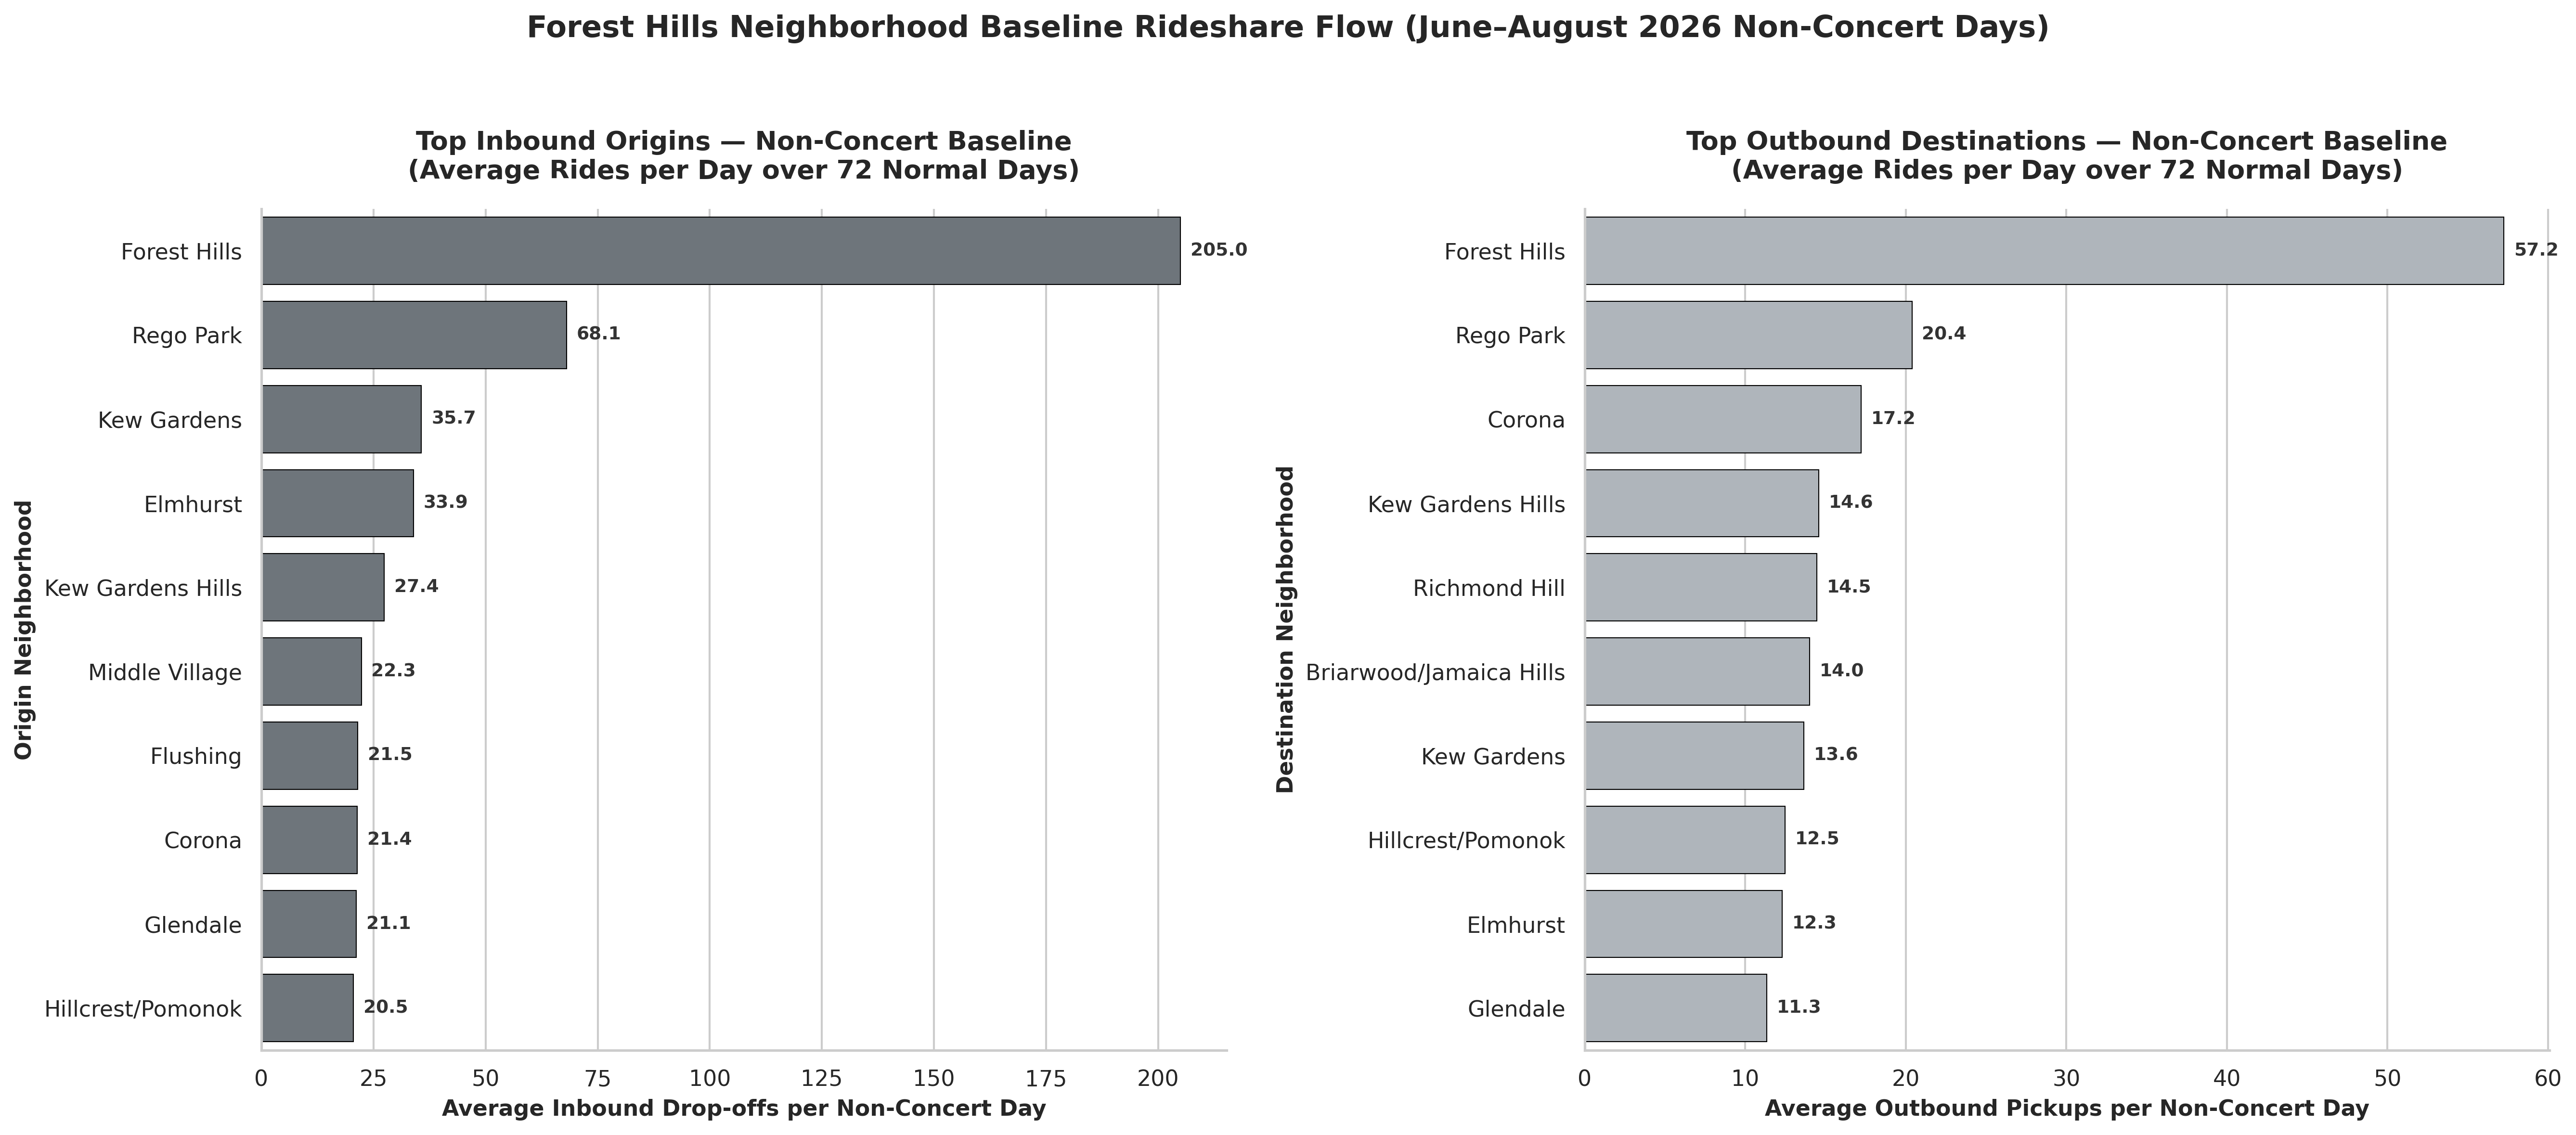


Success! Non-concert baseline visualization saved to 'forest_hills_2026_non_concert_baseline.png'.


In [7]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
TAXI_ZONE_LOOKUP_PATH = "taxi_zone_lookup.csv"

FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95  # Forest Hills Taxi Zone ID

if not os.path.exists(TAXI_ZONE_LOOKUP_PATH):
    raise FileNotFoundError(f"'{TAXI_ZONE_LOOKUP_PATH}' not found in Colab workspace.")

# ==========================================
# 2. DATA PROCESSING FOR NON-CONCERT DAYS
# ==========================================
inbound_control_list = []
outbound_control_list = []
all_non_concert_dates = set()

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 parquet file for non-concert baseline...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID']
    df = pd.read_parquet(file_path, columns=columns)

    # Parse timestamps
    dt = pd.to_datetime(df['pickup_datetime'])
    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])

    df['calendar_date_str'] = dt.dt.date.astype(str)

    # Identify non-concert days within June - August 2026
    is_non_concert = (~df['calendar_date_str'].isin(concert_set)) & (df['calendar_date_str'] >= "2026-06-01") & (df['calendar_date_str'] <= "2026-08-31")

    # Track unique non-concert dates
    valid_dates = df.loc[is_non_concert, 'calendar_date_str'].unique()
    all_non_concert_dates.update(valid_dates)

    # Time window filters
    dropoff_hour = dropoff_dt.dt.hour
    dropoff_minute = dropoff_dt.dt.minute
    inbound_mask = (df['DOLocationID'] == VENUE_ZONE_ID) & (
        ((dropoff_hour >= 17) & (dropoff_hour < 20)) |
        ((dropoff_hour == 20) & (dropoff_minute <= 30))
    )

    pickup_hour = dt.dt.hour
    pickup_minute = dt.dt.minute
    outbound_mask = (df['PULocationID'] == VENUE_ZONE_ID) & (
        ((pickup_hour >= 22) & (pickup_hour <= 23)) |
        ((pickup_hour == 0) & (pickup_minute <= 30))
    )

    inbound_control_list.append(df[is_non_concert & inbound_mask][['PULocationID']])
    outbound_control_list.append(df[is_non_concert & outbound_mask][['DOLocationID']])

num_non_concert_days = len(all_non_concert_dates)
print(f"Total non-concert days identified across June-August 2026: {num_non_concert_days}")

if not inbound_control_list and not outbound_control_list:
    raise ValueError("No valid non-concert data processed.")

in_control_df = pd.concat(inbound_control_list, ignore_index=True) if inbound_control_list else pd.DataFrame(columns=['PULocationID'])
out_control_df = pd.concat(outbound_control_list, ignore_index=True) if outbound_control_list else pd.DataFrame(columns=['DOLocationID'])

# ==========================================
# 3. AGGREGATION & DAILY AVERAGE CALCULATION
# ==========================================
in_agg = in_control_df.groupby('PULocationID').size().reset_index(name='total_trips')
out_agg = out_control_df.groupby('DOLocationID').size().reset_index(name='total_trips')

# Calculate average rides per non-concert day
in_agg['avg_per_non_concert_day'] = in_agg['total_trips'] / max(num_non_concert_days, 1)
out_agg['avg_per_non_concert_day'] = out_agg['total_trips'] / max(num_non_concert_days, 1)

# Load Taxi Zone Names
zone_lookup = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
zone_dict = dict(zip(zone_lookup['LocationID'], zone_lookup['Zone']))

in_agg['Neighborhood'] = in_agg['PULocationID'].map(zone_dict)
out_agg['Neighborhood'] = out_agg['DOLocationID'].map(zone_dict)

top_origins_nc = in_agg.sort_values(by='avg_per_non_concert_day', ascending=False).head(10)
top_destinations_nc = out_agg.sort_values(by='avg_per_non_concert_day', ascending=False).head(10)

print("\n--- Top Inbound Origins (Non-Concert Daily Average) ---")
print(top_origins_nc[['Neighborhood', 'total_trips', 'avg_per_non_concert_day']].to_string(index=False))

print("\n--- Top Outbound Destinations (Non-Concert Daily Average) ---")
print(top_destinations_nc[['Neighborhood', 'total_trips', 'avg_per_non_concert_day']].to_string(index=False))

# ==========================================
# 4. SEABORN VISUALIZATION (NON-CONCERT BASELINE)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(18, 8), dpi=300)

# Panel 1: Top Inbound Origins (Non-Concert Daily Average)
sns.barplot(
    data=top_origins_nc, x='avg_per_non_concert_day', y='Neighborhood',
    color='#6c757d', ax=axes[0], edgecolor="black", linewidth=0.5
)
axes[0].set_title(f"Top Inbound Origins — Non-Concert Baseline\n(Average Rides per Day over {num_non_concert_days} Normal Days)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Average Inbound Drop-offs per Non-Concert Day", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Origin Neighborhood", fontsize=11, fontweight='semibold')

# Panel 2: Top Outbound Destinations (Non-Concert Daily Average)
sns.barplot(
    data=top_destinations_nc, x='avg_per_non_concert_day', y='Neighborhood',
    color='#adb5bd', ax=axes[1], edgecolor="black", linewidth=0.5
)
axes[1].set_title(f"Top Outbound Destinations — Non-Concert Baseline\n(Average Rides per Day over {num_non_concert_days} Normal Days)", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Average Outbound Pickups per Non-Concert Day", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Destination Neighborhood", fontsize=11, fontweight='semibold')

# Annotate exact values on bars
for ax in axes:
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{width:.1f}',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        fontsize=9, fontweight='bold', color='#333333',
                        textcoords='offset points', xytext=(5, 0))
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle("Forest Hills Neighborhood Baseline Rideshare Flow (June–August 2026 Non-Concert Days)",
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])

output_filename = "forest_hills_2026_non_concert_baseline.png"
plt.savefig(output_filename, bbox_inches='tight')
plt.show()
print(f"\nSuccess! Non-concert baseline visualization saved to '{output_filename}'.")

In [ ]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
TAXI_ZONE_LOOKUP_PATH = "taxi_zone_lookup.csv"

FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium for June, July & August
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)

# Time windows
INBOUND_START, INBOUND_END = "17:00:00", "20:30:00"
OUTBOUND_START, OUTBOUND_END = "22:00:00", "00:30:00"
VENUE_ZONE_ID = 95  # Forest Hills Taxi Zone ID

if not os.path.exists(TAXI_ZONE_LOOKUP_PATH):
    raise FileNotFoundError(f"'{TAXI_ZONE_LOOKUP_PATH}' not found in Colab workspace.")

# ==========================================
# 2. DATA PROCESSING WITH MIDNIGHT ADJUSTMENT
# ==========================================
inbound_concert_list = []
outbound_concert_list = []
inbound_control_list = []
outbound_control_list = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 parquet file...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID']
    df = pd.read_parquet(file_path, columns=columns)

    # Parse timestamps
    dt = pd.to_datetime(df['pickup_datetime'])
    dropoff_dt = pd.to_datetime(df['dropoff_datetime'])

    df['calendar_date_str'] = dt.dt.date.astype(str)
    df['pickup_time'] = dt.dt.time.astype(str)
    df['dropoff_time'] = dropoff_dt.dt.time.astype(str)
    df['day_of_week'] = dt.dt.dayofweek

    # FIX: Adjust event date for post-midnight trips (hours 0-3 belong to previous night's event)
    event_dates = dt.dt.date.copy()
    early_morning_mask = dt.dt.hour < 4
    event_dates[early_morning_mask] = (dt[early_morning_mask] - pd.Timedelta(days=1)).dt.date
    df['event_date_str'] = event_dates.astype(str)

    # Identify concert vs non-concert based on event date
    is_concert_event = df['event_date_str'].isin(concert_set)

    # Define filters
    inbound_mask = (df['DOLocationID'] == VENUE_ZONE_ID) & (df['dropoff_time'] >= INBOUND_START) & (df['dropoff_time'] <= INBOUND_END)
    outbound_mask = (df['PULocationID'] == VENUE_ZONE_ID) & (df['pickup_time'] >= OUTBOUND_START) & (df['pickup_time'] <= OUTBOUND_END)

    # 1. Concert Events Data (using event_date_str)
    inbound_concert_list.append(df[is_concert_event & inbound_mask][['event_date_str', 'PULocationID']])
    outbound_concert_list.append(df[is_concert_event & outbound_mask][['event_date_str', 'DOLocationID']])

    # 2. Control Baseline Data
    concert_dow = df[is_concert_event]['day_of_week'].unique()
    control_mask = (~is_concert_event) & (df['day_of_week'].isin(concert_dow))

    inbound_control_list.append(df[control_mask & inbound_mask][['calendar_date_str', 'PULocationID']])
    outbound_control_list.append(df[control_mask & outbound_mask][['calendar_date_str', 'DOLocationID']])

if not inbound_concert_list:
    raise ValueError("No valid data processed.")

in_concert_df = pd.concat(inbound_concert_list, ignore_index=True)
out_concert_df = pd.concat(outbound_concert_list, ignore_index=True)
in_control_df = pd.concat(inbound_control_list, ignore_index=True)
out_control_df = pd.concat(outbound_control_list, ignore_index=True)

num_concert_days = len(concert_set)
num_control_days = in_control_df['calendar_date_str'].nunique() if not in_control_df.empty else 1

# ==========================================
# 3. AGGREGATION & NET EVENT DELTA
# ==========================================
# Inbound
in_concert_agg = in_concert_df.groupby('PULocationID').size().reset_index(name='concert_trips')
in_control_agg = in_control_df.groupby('PULocationID').size().reset_index(name='control_trips') if not in_control_df.empty else pd.DataFrame(columns=['PULocationID', 'control_trips'])

in_merged = pd.merge(in_concert_agg, in_control_agg, on='PULocationID', how='left').fillna(0)
in_merged['baseline_avg_per_day'] = in_merged['control_trips'] / max(num_control_days, 1)
in_merged['net_event_trips'] = (in_merged['concert_trips'] - (in_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Outbound
out_concert_agg = out_concert_df.groupby('DOLocationID').size().reset_index(name='concert_trips')
out_control_agg = out_control_df.groupby('DOLocationID').size().reset_index(name='control_trips') if not out_control_agg.empty else pd.DataFrame(columns=['DOLocationID', 'control_trips'])

out_merged = pd.merge(out_concert_agg, out_control_agg, on='DOLocationID', how='left').fillna(0)
out_merged['baseline_avg_per_day'] = out_merged['control_trips'] / max(num_control_days, 1)
out_merged['net_event_trips'] = (out_merged['concert_trips'] - (out_merged['baseline_avg_per_day'] * num_concert_days)).clip(lower=0)

# Load Taxi Zone Names
zone_lookup = pd.read_csv(TAXI_ZONE_LOOKUP_PATH)
zone_dict = dict(zip(zone_lookup['LocationID'], zone_lookup['Zone']))

in_merged['Neighborhood'] = in_merged['PULocationID'].map(zone_dict)
out_merged['Neighborhood'] = out_merged['DOLocationID'].map(zone_dict)

top_origins = in_merged.sort_values(by='net_event_trips', ascending=False).head(10)
top_destinations = out_merged.sort_values(by='net_event_trips', ascending=False).head(10)

# ==========================================
# 4. SEABORN VISUALIZATION (TWO-PANEL HORIZONTAL BAR CHART)
# ==========================================
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 8), dpi=300)

# Panel 1: Top Inbound Origins
sns.barplot(
    data=top_origins, x='net_event_trips', y='Neighborhood',
    color='#4C72B0', ax=axes[0], edgecolor="black", linewidth=0.5
)
axes[0].set_title("Top Inbound Origins to Forest Hills Stadium\n(Net Baseline-Adjusted Trips)", fontsize=13, fontweight='bold', pad=15)
axes[0].set_xlabel("Net Event Trips", fontsize=11, fontweight='semibold')
axes[0].set_ylabel("Origin Neighborhood", fontsize=11, fontweight='semibold')

# Panel 2: Top Outbound Destinations
sns.barplot(
    data=top_destinations, x='net_event_trips', y='Neighborhood',
    color='#DD8452', ax=axes[1], edgecolor="black", linewidth=0.5
)
axes[1].set_title("Top Outbound Destinations from Forest Hills Stadium\n(Net Baseline-Adjusted Trips)", fontsize=13, fontweight='bold', pad=15)
axes[1].set_xlabel("Net Event Trips", fontsize=11, fontweight='semibold')
axes[1].set_ylabel("Destination Neighborhood", fontsize=11, fontweight='semibold')

# Annotate exact trip values on the bars
for ax in axes:
    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.annotate(f'{int(width):,}',
                        (width, p.get_y() + p.get_height() / 2.),
                        ha='left', va='center',
                        fontsize=9, fontweight='bold', color='#333333',
                        textcoords='offset points', xytext=(5, 0))
    sns.despine(ax=ax, top=True, right=True)

plt.suptitle("Forest Hills Stadium Net Rideshare Flow Analysis (June–August 2026)",
             fontsize=15, fontweight='bold', y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.95])

output_filename = "forest_hills_2026_flow_seaborn.png"
plt.savefig(output_filename, bbox_inches='tight')
plt.show()
print(f"Success! Seaborn flow visualization saved to '{output_filename}'.")

Processing June 2026 parquet file...
Processing July 2026 parquet file...
Processing August 2026 parquet file...


Fetching 311 service requests from NYC Open Data API for ZIP 11375...


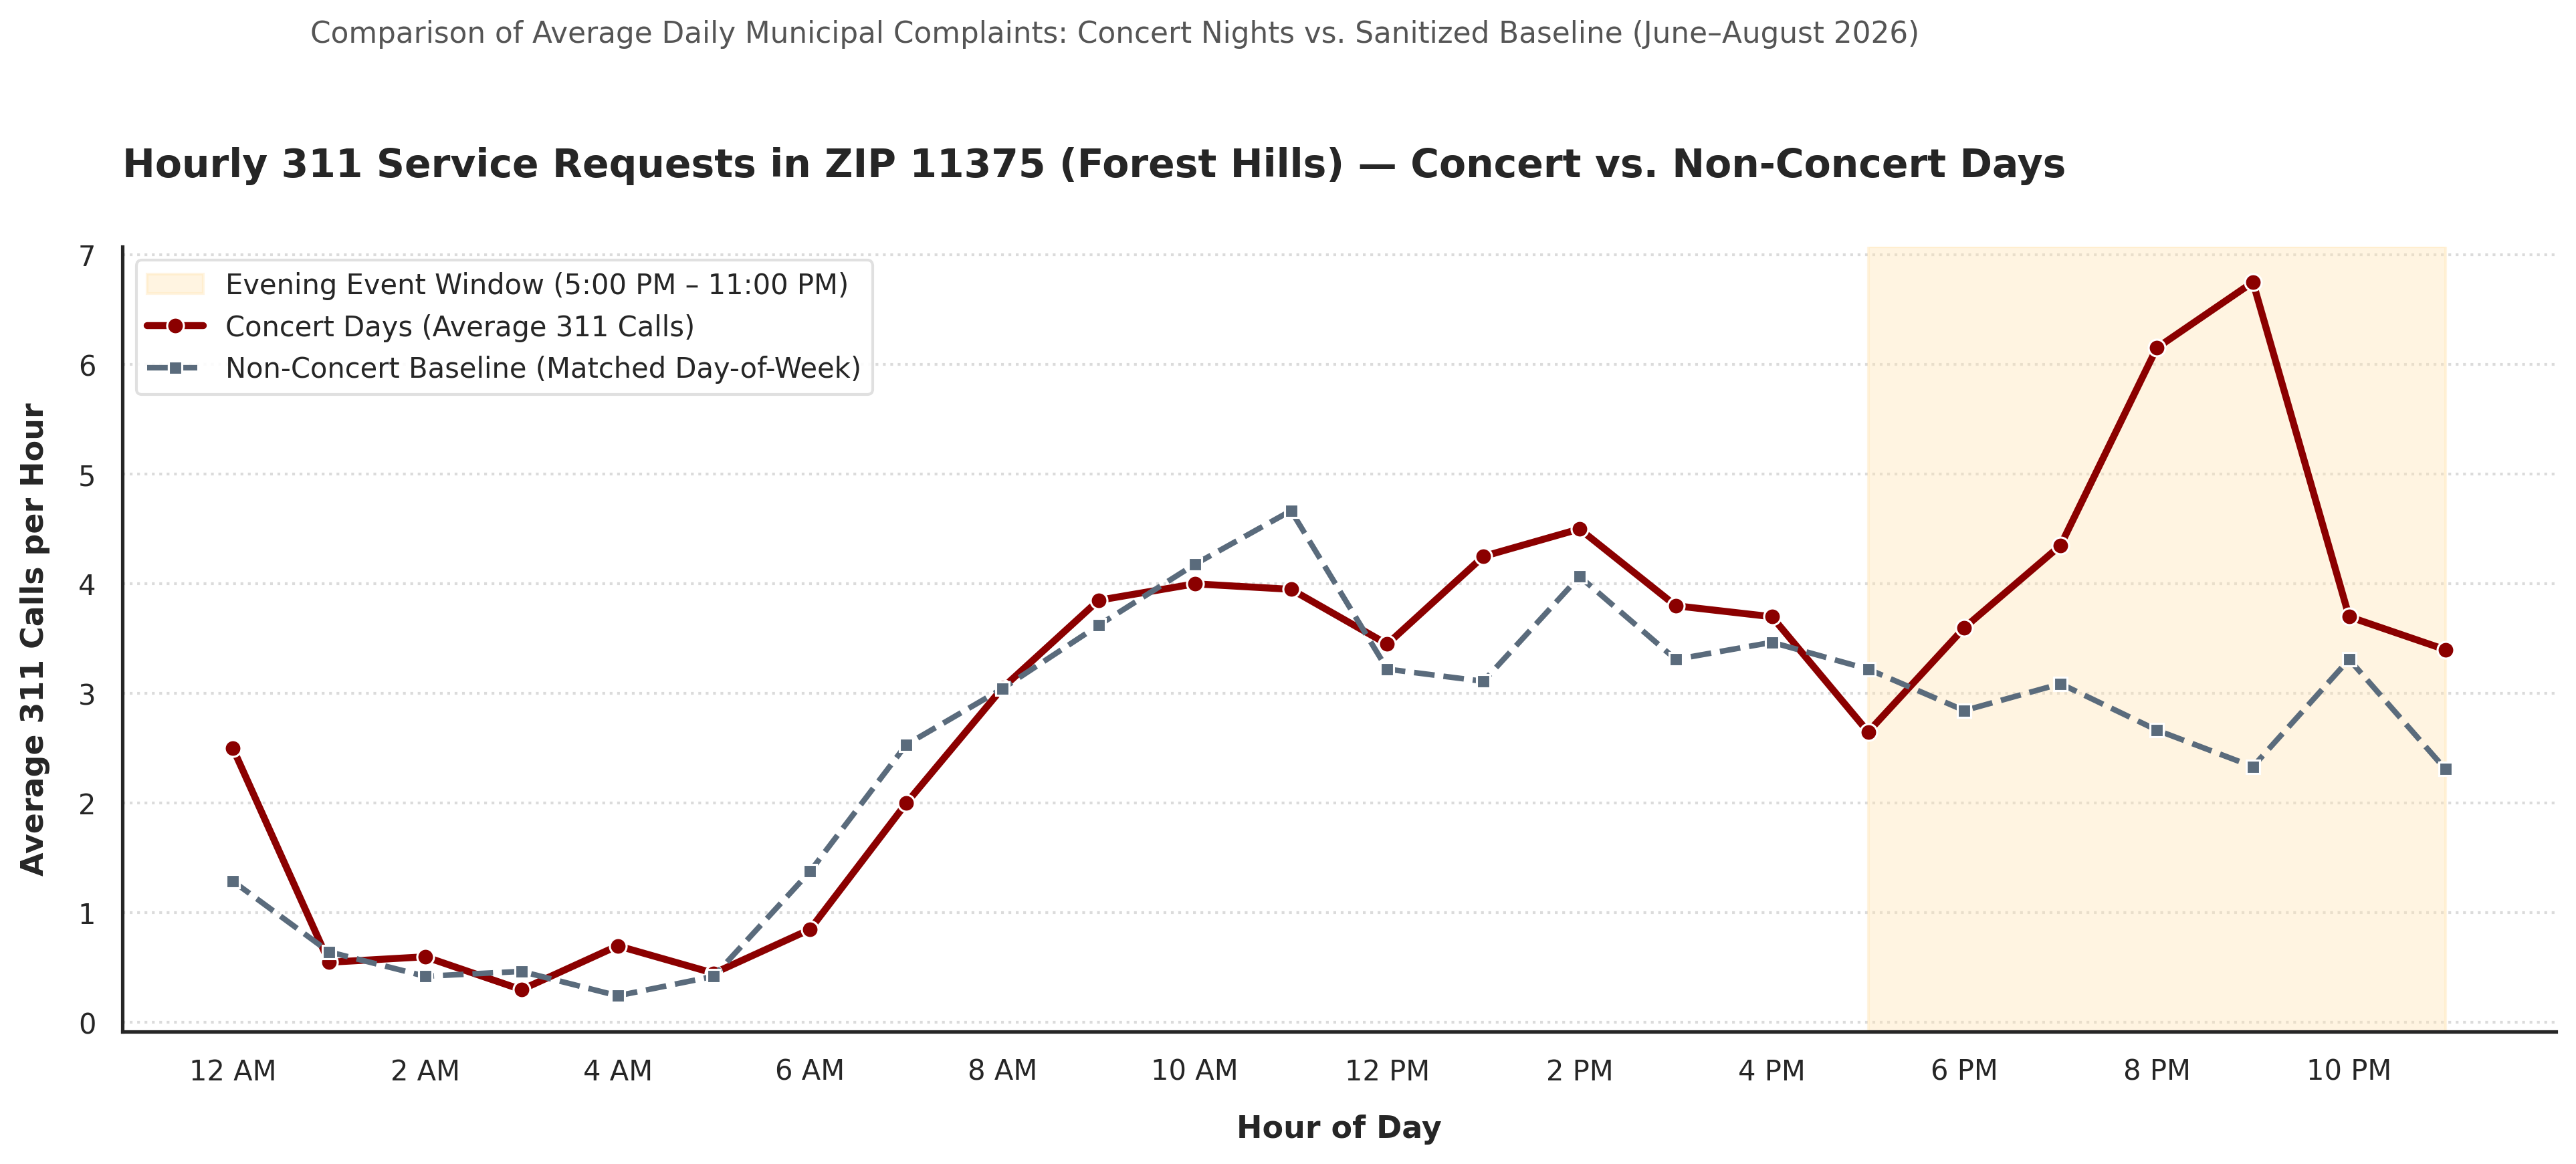

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)
    df_311['hour'] = created_dt.dt.hour
    df_311['day_of_week'] = created_dt.dt.dayofweek

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Separate concert vs control (matching day-of-week profile)
    is_concert = df_311['date_str'].isin(concert_set)
    concert_dow = df_311[is_concert]['day_of_week'].unique()
    control_mask = (~is_concert) & (df_311['day_of_week'].isin(concert_dow))

    concert_df = df_311[is_concert]
    control_df = df_311[control_mask]

    num_concert_days = len(concert_set)
    num_control_days = control_df['date_str'].nunique() if not control_df.empty else 1

    # Aggregate hourly averages normalized by day counts
    c_counts = concert_df.groupby('hour').size().reset_index(name='total_calls')
    c_counts['avg_calls'] = c_counts['total_calls'] / num_concert_days

    ctl_counts = control_df.groupby('hour').size().reset_index(name='total_calls')
    ctl_counts['avg_calls'] = ctl_counts['total_calls'] / num_control_days

    full_hours = pd.DataFrame({'hour': range(24)})
    plot_df = full_hours.merge(c_counts[['hour', 'avg_calls']], on='hour', how='left') \
                        .merge(ctl_counts[['hour', 'avg_calls']], on='hour', suffixes=('_concert', '_baseline'), how='left').fillna(0)

    # ==========================================
    # 2. PLOTTING CONCERT VS NON-CONCERT 311 CALLS
    # ==========================================
    plt.figure(figsize=(13, 6.5), dpi=300)
    sns.set_theme(style="white")

    # Highlight evening event window (5 PM - 11 PM)
    plt.axvspan(17, 23, color='#FFE5B4', alpha=0.4, label='Evening Event Window (5:00 PM – 11:00 PM)')

    sns.lineplot(
        data=plot_df, x='hour', y='avg_calls_concert',
        color='#8B0000', linewidth=2.5, marker='o', markersize=6,
        label='Concert Days (Average 311 Calls)'
    )
    sns.lineplot(
        data=plot_df, x='hour', y='avg_calls_baseline',
        color='#5A6B7C', linewidth=2, linestyle='--', marker='s', markersize=5,
        label='Non-Concert Baseline (Matched Day-of-Week)'
    )

    plt.title("Hourly 311 Service Requests in ZIP 11375 (Forest Hills) — Concert vs. Non-Concert Days", fontsize=14, fontweight='bold', pad=25, loc='left')
    plt.suptitle("Comparison of Average Daily Municipal Complaints: Concert Nights vs. Sanitized Baseline (June–August 2026)", fontsize=10.5, color='#555555', x=0.125, y=0.92, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Average 311 Calls per Hour", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(range(0, 24, 2), hour_labels, fontsize=10)
    plt.yticks(fontsize=10)

    plt.grid(axis='y', linestyle=':', alpha=0.7, color='#CCCCCC')
    sns.despine(top=True, right=True)

    plt.legend(frameon=True, facecolor='white', edgecolor='#DDDDDD', fontsize=10, loc='upper left', framealpha=0.9)
    plt.tight_layout(rect=[0, 0.03, 1, 0.90])

    plt.show()

Fetching 311 service requests from NYC Open Data API for ZIP 11375...


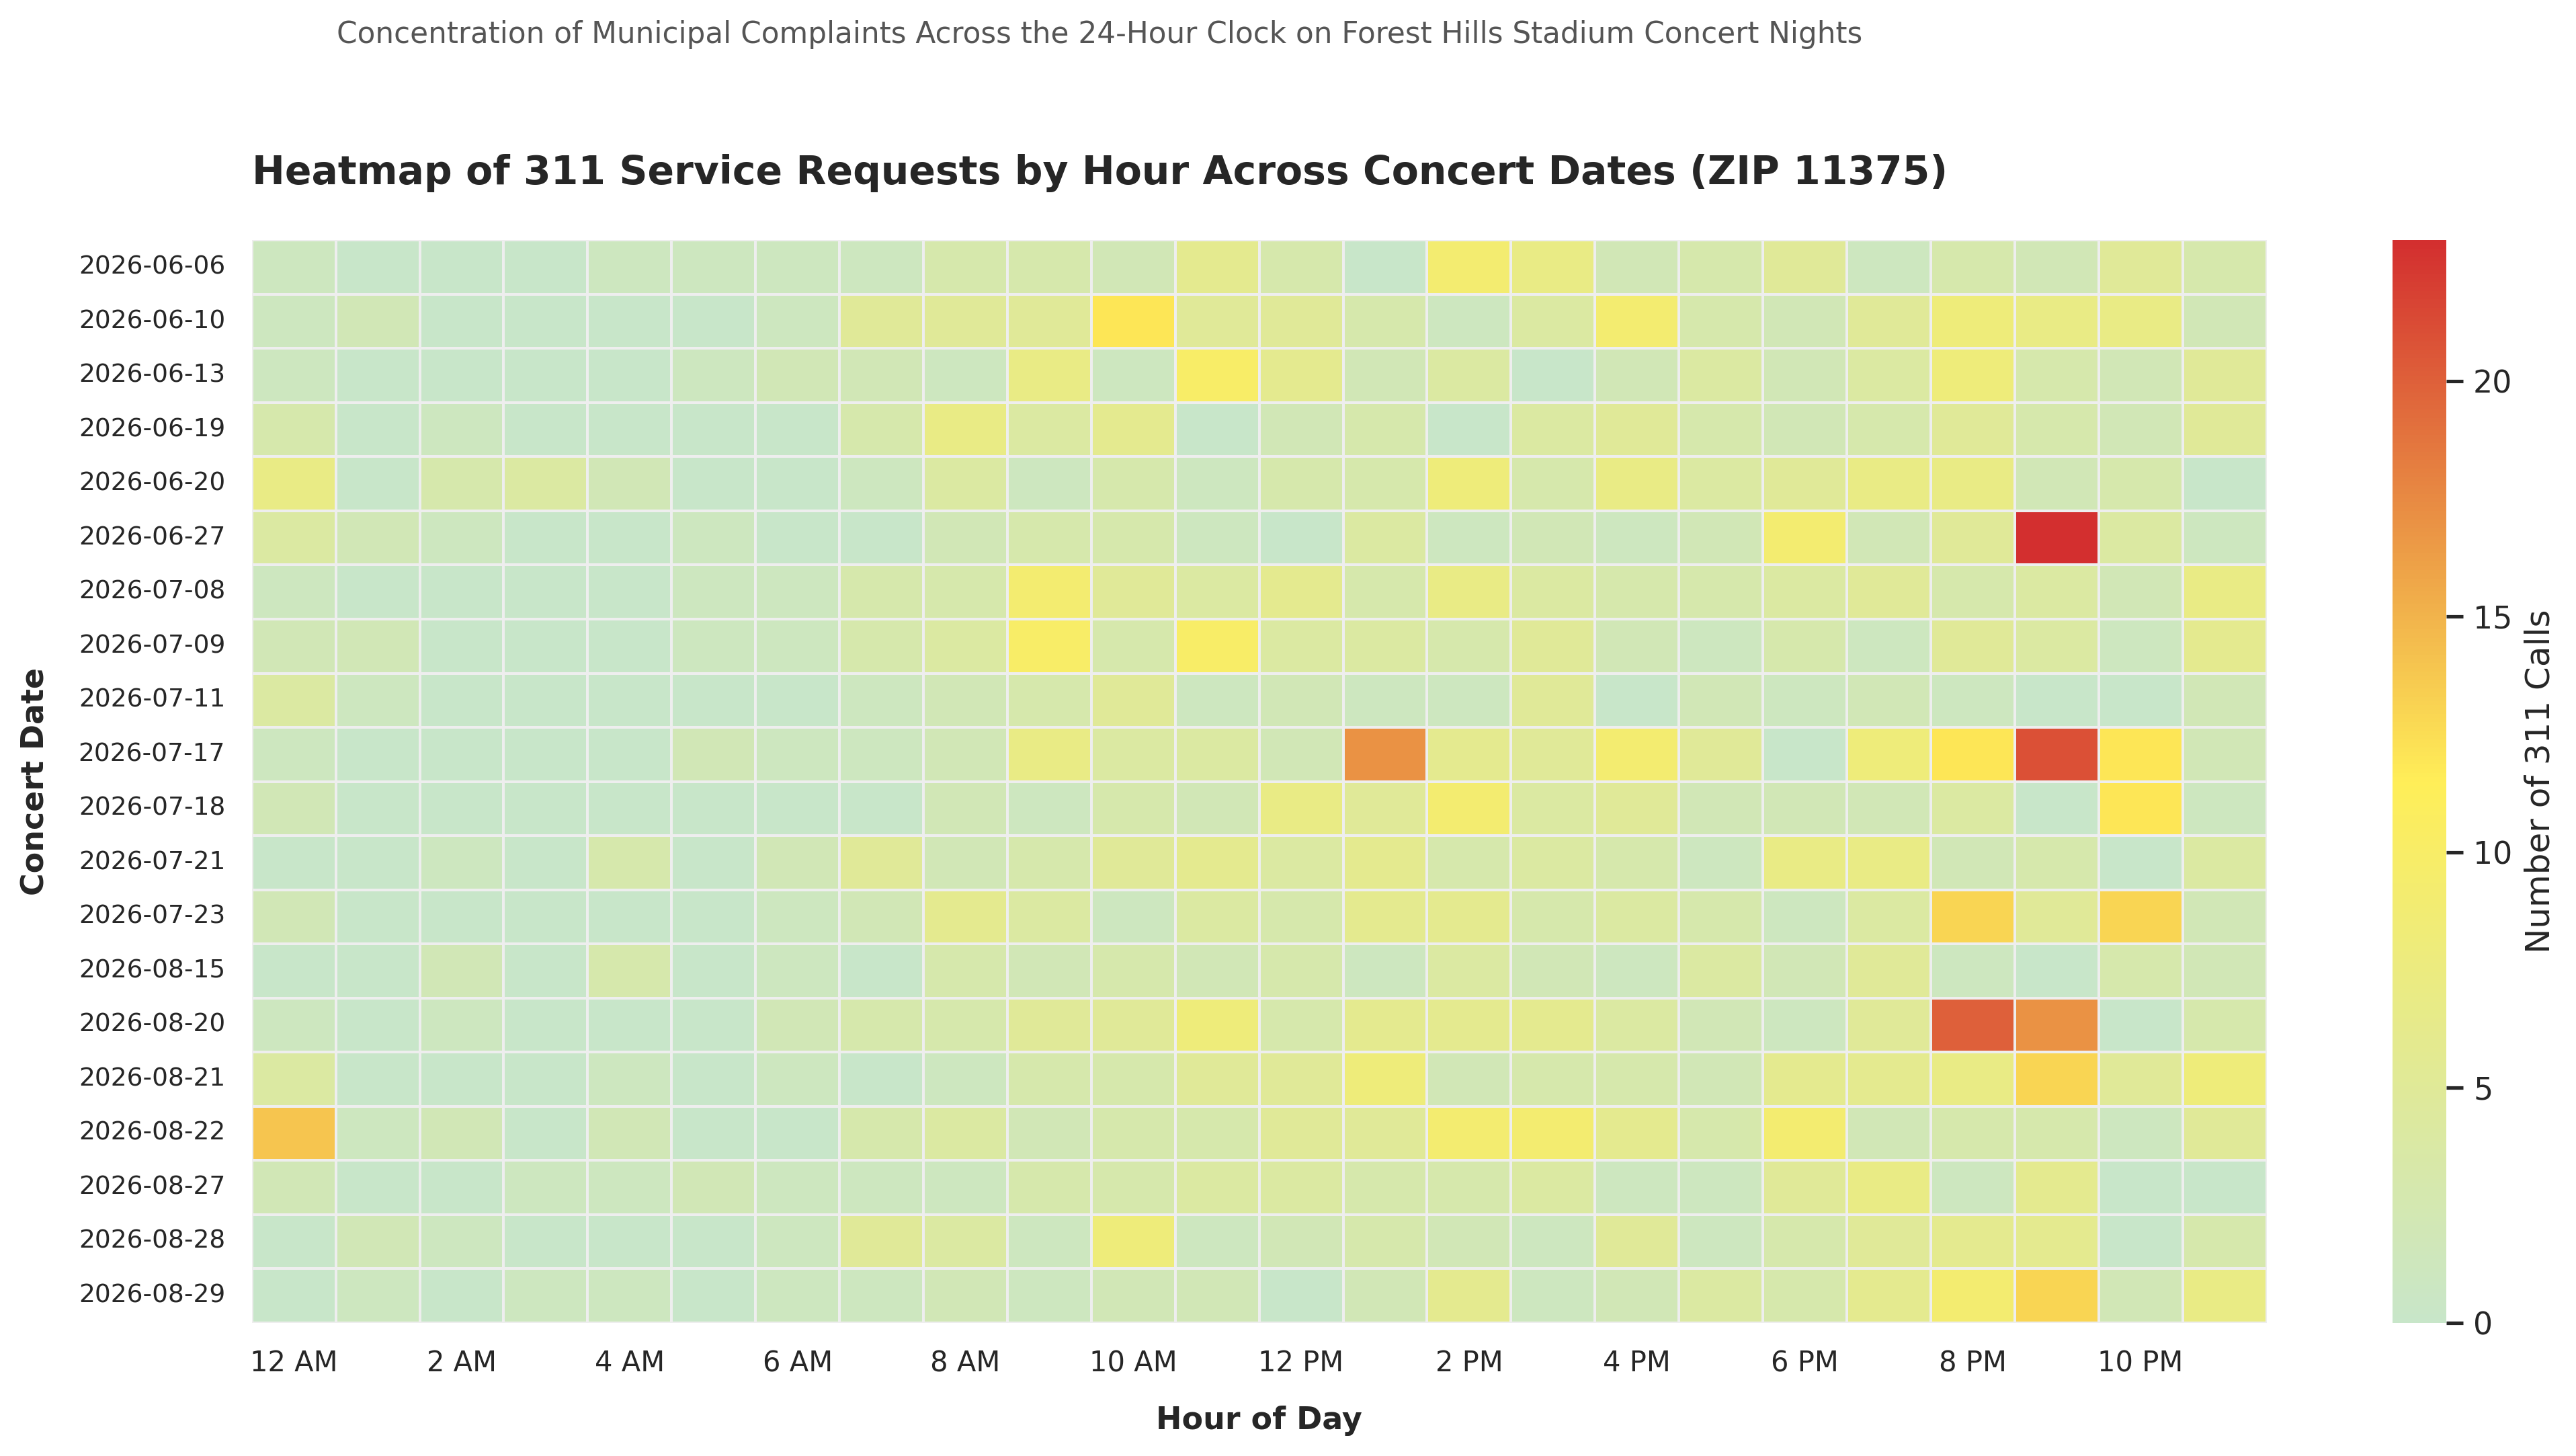

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    created_dt = pd.to_datetime(df_311['created_date'])
    df_311['date_str'] = created_dt.dt.date.astype(str)
    df_311['hour'] = created_dt.dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter for concert days only
    concert_311 = df_311[df_311['date_str'].isin(concert_set)].copy()

    # Aggregate counts by Date and Hour
    heatmap_data = concert_311.groupby(['date_str', 'hour']).size().reset_index(name='call_count')

    # Create pivot table: Rows = Concert Dates, Columns = Hours (0-23)
    pivot_df = heatmap_data.pivot(index='date_str', columns='hour', values='call_count').fillna(0)

    # Ensure all 24 hours (0-23) are present as columns
    for h in range(24):
        if h not in pivot_df.columns:
            pivot_df[h] = 0
    pivot_df = pivot_df[sorted(pivot_df.columns)]

    # Ensure all concert dates are present as rows
    all_concert_dates_sorted = sorted(list(concert_set))
    pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

    # ==========================================
    # 2. PLOT HEATMAP (Light Green for Low)
    # ==========================================
    plt.figure(figsize=(14, 8), dpi=300)
    sns.set_theme(style="white")

    # Define custom colormap: Light Green -> Soft Yellow -> Dark Red
    custom_cmap = LinearSegmentedColormap.from_list(
        "lightgreen_yellow_red",
        ["#C8E6C9", "#FFEE58", "#D32F2F"]
    )

    ax = sns.heatmap(
        pivot_df,
        cmap=custom_cmap,
        linewidths=0.5,
        linecolor='#EEEEEE',
        cbar_kws={'label': 'Number of 311 Calls'}
    )

    plt.title("Heatmap of 311 Service Requests by Hour Across Concert Dates (ZIP 11375)", fontsize=14, fontweight='bold', pad=20, loc='left')
    plt.suptitle("Concentration of Municipal Complaints Across the 24-Hour Clock on Forest Hills Stadium Concert Nights", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(ticks=[i + 0.5 for i in range(0, 24, 2)], labels=hour_labels, rotation=0, fontsize=10)
    plt.yticks(fontsize=9, rotation=0)

    plt.tight_layout(rect=[0, 0.03, 1, 0.91])
    plt.show()

Fetching 311 service requests from NYC Open Data API for ZIP 11375...


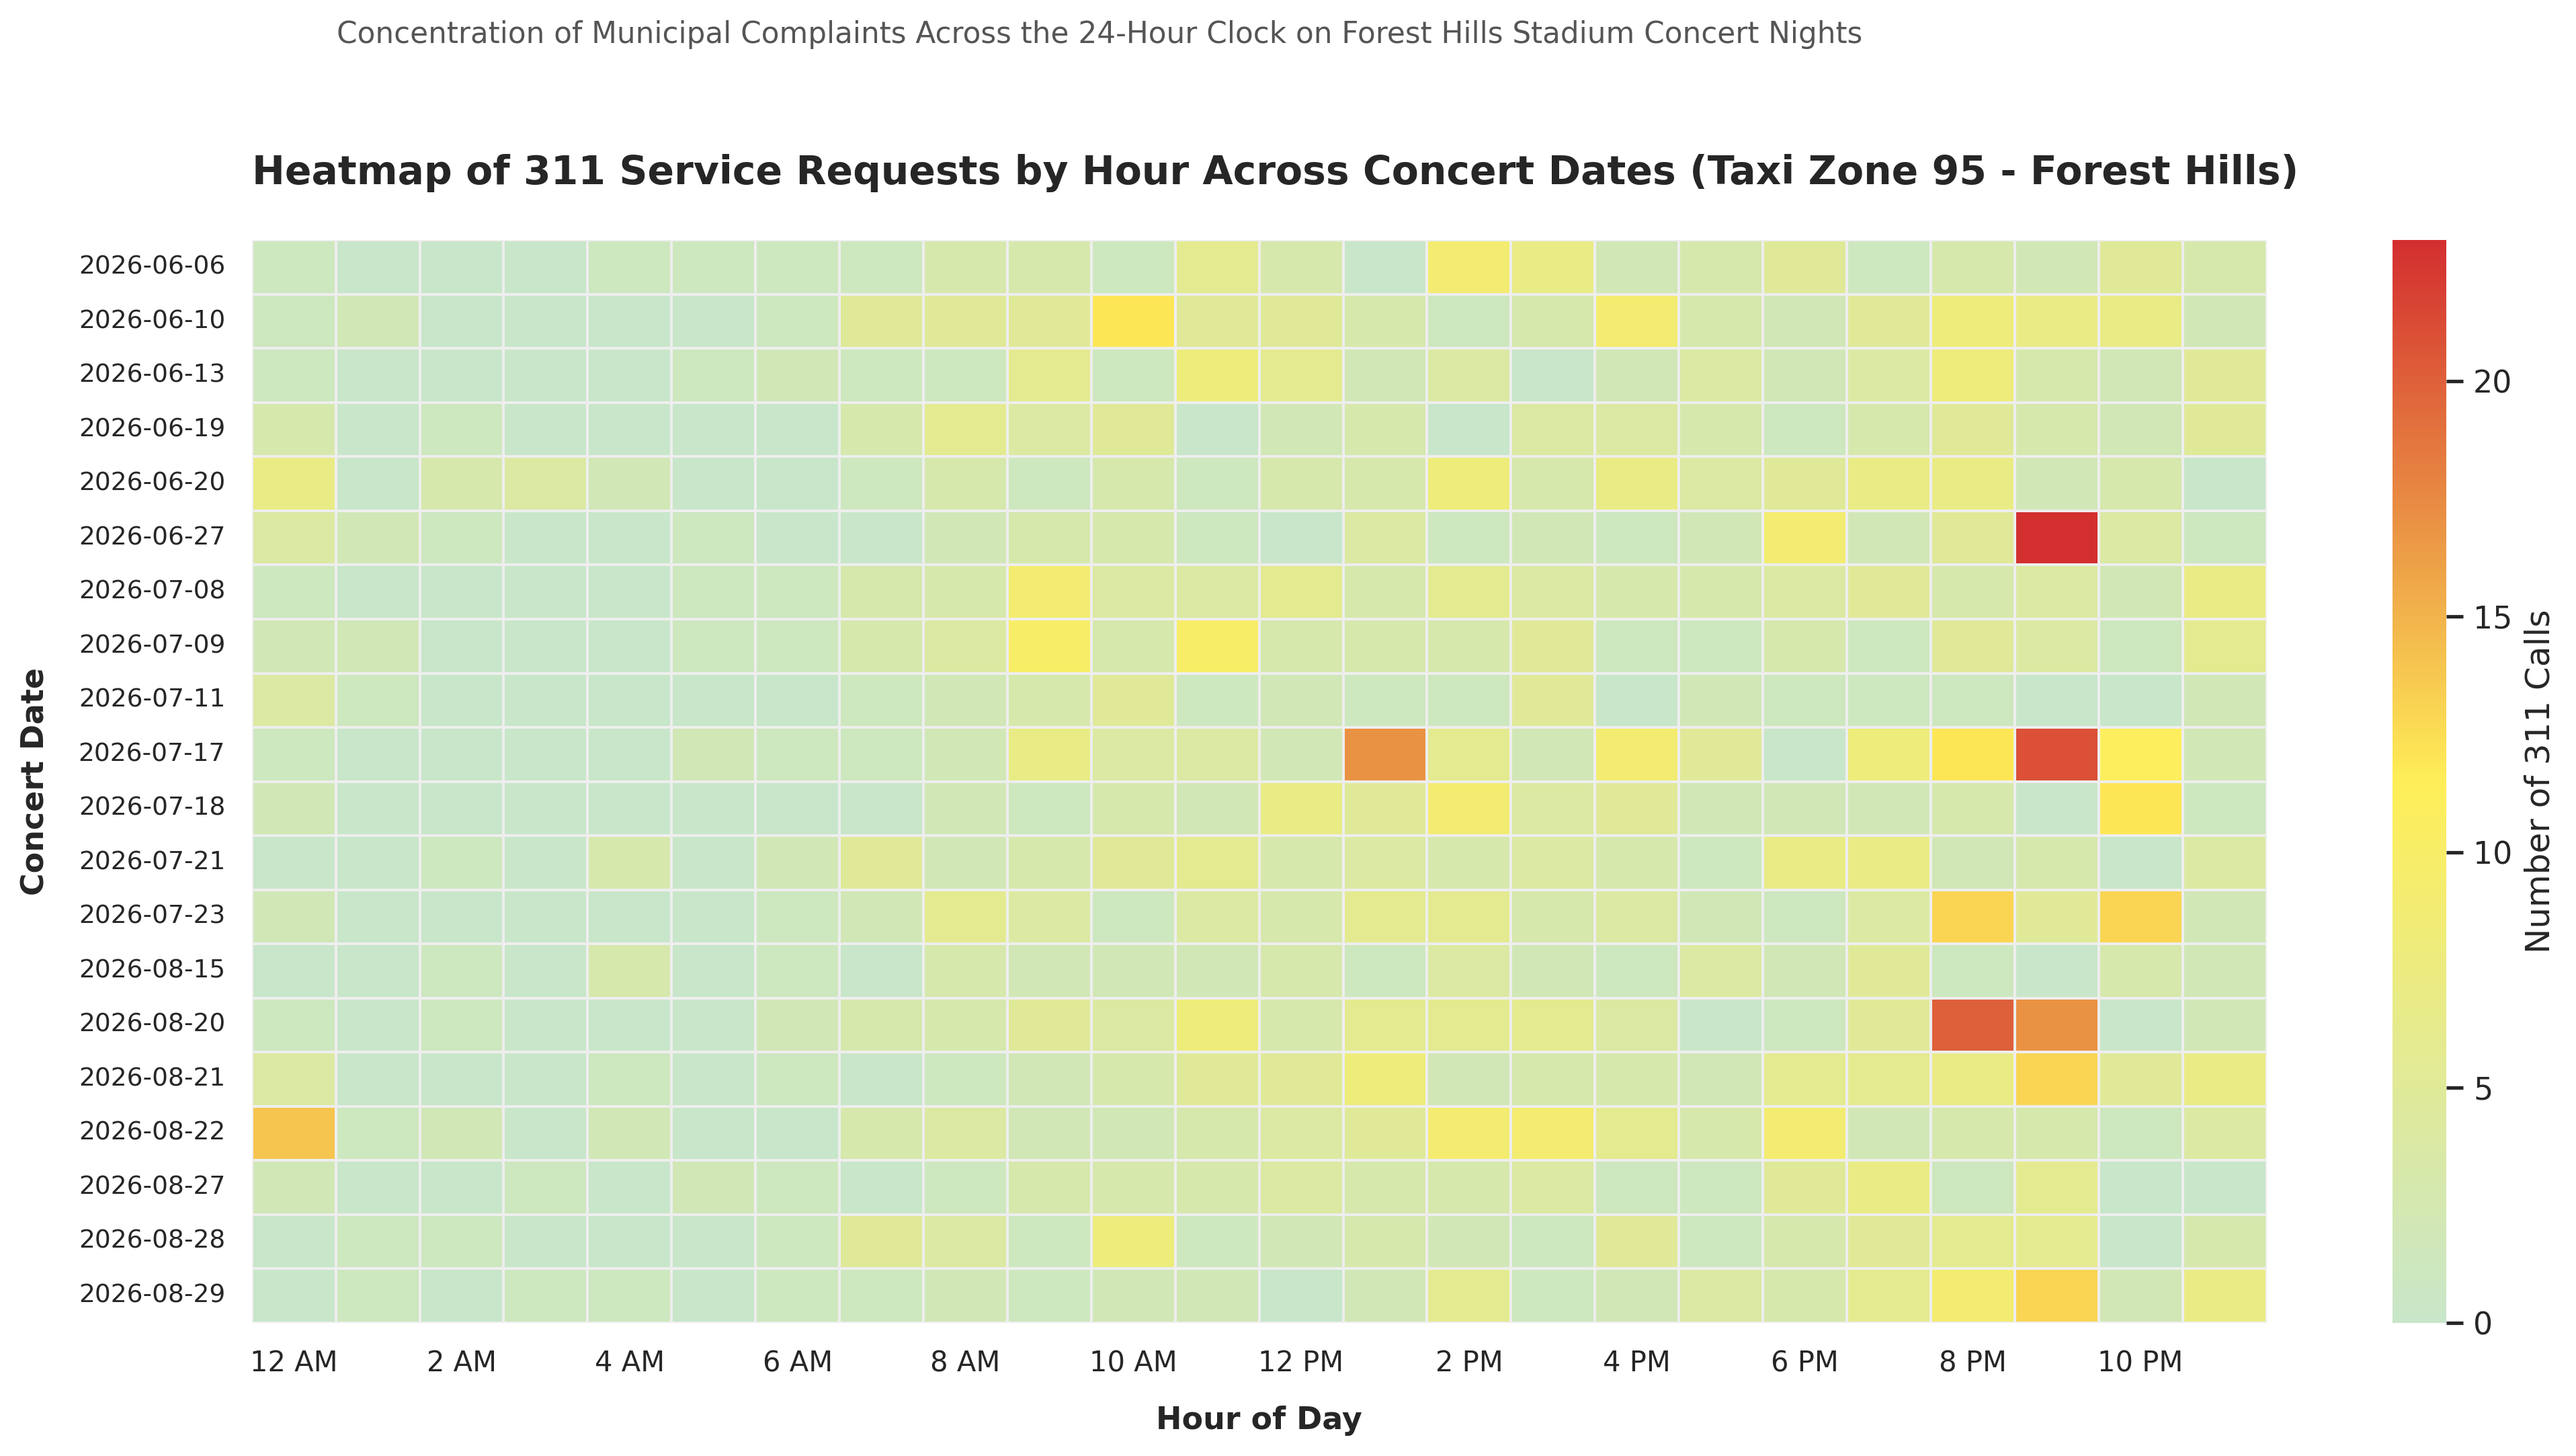

In [19]:
import os
import urllib.request
import zipfile
import pandas as pd
import geopandas as gpd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. DOWNLOAD TAXI ZONES & ISOLATE ZONE 95
# ==========================================
SHAPEFILE_URL = "https://d37ci6vzurychx.cloudfront.net/misc/taxi_zones.zip"
ZIP_FILENAME = "taxi_zones.zip"
EXTRACT_DIR = "taxi_zones_data"

if not os.path.exists(ZIP_FILENAME):
    print("Downloading NYC Taxi Zones shapefile...")
    urllib.request.urlretrieve(SHAPEFILE_URL, ZIP_FILENAME)

if not os.path.exists(EXTRACT_DIR):
    os.makedirs(EXTRACT_DIR, exist_ok=True)
    with zipfile.ZipFile(ZIP_FILENAME, 'r') as zip_ref:
        zip_ref.extractall(EXTRACT_DIR)

shp_path = None
for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.endswith(".shp"):
            shp_path = os.path.join(root, file)
            break

zones_gdf = gpd.read_file(shp_path)
if zones_gdf.crs != "EPSG:4326":
    zones_gdf = zones_gdf.to_crs("EPSG:4326")

# Isolate Taxi Zone 95 (Forest Hills Stadium area)
zone_95 = zones_gdf[zones_gdf['LocationID'].astype(int) == 95].copy()

# ==========================================
# 2. FETCH 311 DATA FROM NYC OPEN DATA API
# ==========================================
url = "https://data.cityofnewyork.us/resource/erm2-nwe9.json"
where_clause = "incident_zip='11375' AND created_date >= '2026-06-01T00:00:00' AND created_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "unique_key, created_date, incident_zip, complaint_type, latitude, longitude"
}

print("Fetching 311 service requests from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No data returned or check API limits/filters.")
else:
    df_311 = pd.DataFrame(data)

    # Drop rows without coordinate data and convert to float
    df_311 = df_311.dropna(subset=['latitude', 'longitude']).copy()
    df_311['latitude'] = df_311['latitude'].astype(float)
    df_311['longitude'] = df_311['longitude'].astype(float)

    # Convert to GeoDataFrame and perform spatial join with Zone 95
    gdf_311 = gpd.GeoDataFrame(
        df_311,
        geometry=gpd.points_from_xy(df_311['longitude'], df_311['latitude']),
        crs="EPSG:4326"
    )

    # Keep only 311 service requests strictly falling within Taxi Zone 95
    joined_gdf = gpd.sjoin(gdf_311, zone_95, how="inner", predicate="within")

    created_dt = pd.to_datetime(joined_gdf['created_date'])
    joined_gdf['date_str'] = created_dt.dt.date.astype(str)
    joined_gdf['hour'] = created_dt.dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter for concert days only
    concert_311 = joined_gdf[joined_gdf['date_str'].isin(concert_set)].copy()

    # Aggregate counts by Date and Hour
    heatmap_data = concert_311.groupby(['date_str', 'hour']).size().reset_index(name='call_count')

    # Create pivot table: Rows = Concert Dates, Columns = Hours (0-23)
    pivot_df = heatmap_data.pivot(index='date_str', columns='hour', values='call_count').fillna(0)

    # Ensure all 24 hours (0-23) are present as columns
    for h in range(24):
        if h not in pivot_df.columns:
            pivot_df[h] = 0
    pivot_df = pivot_df[sorted(pivot_df.columns)]

    # Ensure all concert dates are present as rows
    all_concert_dates_sorted = sorted(list(concert_set))
    pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

    # ==========================================
    # 3. PLOT HEATMAP (Light Green for Low)
    # ==========================================
    plt.figure(figsize=(14, 8), dpi=300)
    sns.set_theme(style="white")

    # Define custom colormap: Light Green -> Soft Yellow -> Dark Red
    custom_cmap = LinearSegmentedColormap.from_list(
        "lightgreen_yellow_red",
        ["#C8E6C9", "#FFEE58", "#D32F2F"]
    )

    ax = sns.heatmap(
        pivot_df,
        cmap=custom_cmap,
        linewidths=0.5,
        linecolor='#EEEEEE',
        cbar_kws={'label': 'Number of 311 Calls'}
    )

    plt.title("Heatmap of 311 Service Requests by Hour Across Concert Dates (Taxi Zone 95 - Forest Hills)", fontsize=14, fontweight='bold', pad=20, loc='left')
    plt.suptitle("Concentration of Municipal Complaints Across the 24-Hour Clock on Forest Hills Stadium Concert Nights", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(ticks=[i + 0.5 for i in range(0, 24, 2)], labels=hour_labels, rotation=0, fontsize=10)
    plt.yticks(fontsize=9, rotation=0)

    plt.tight_layout(rect=[0, 0.03, 1, 0.91])
    plt.show()

Fetching NYPD collision data from NYC Open Data API for ZIP 11375...


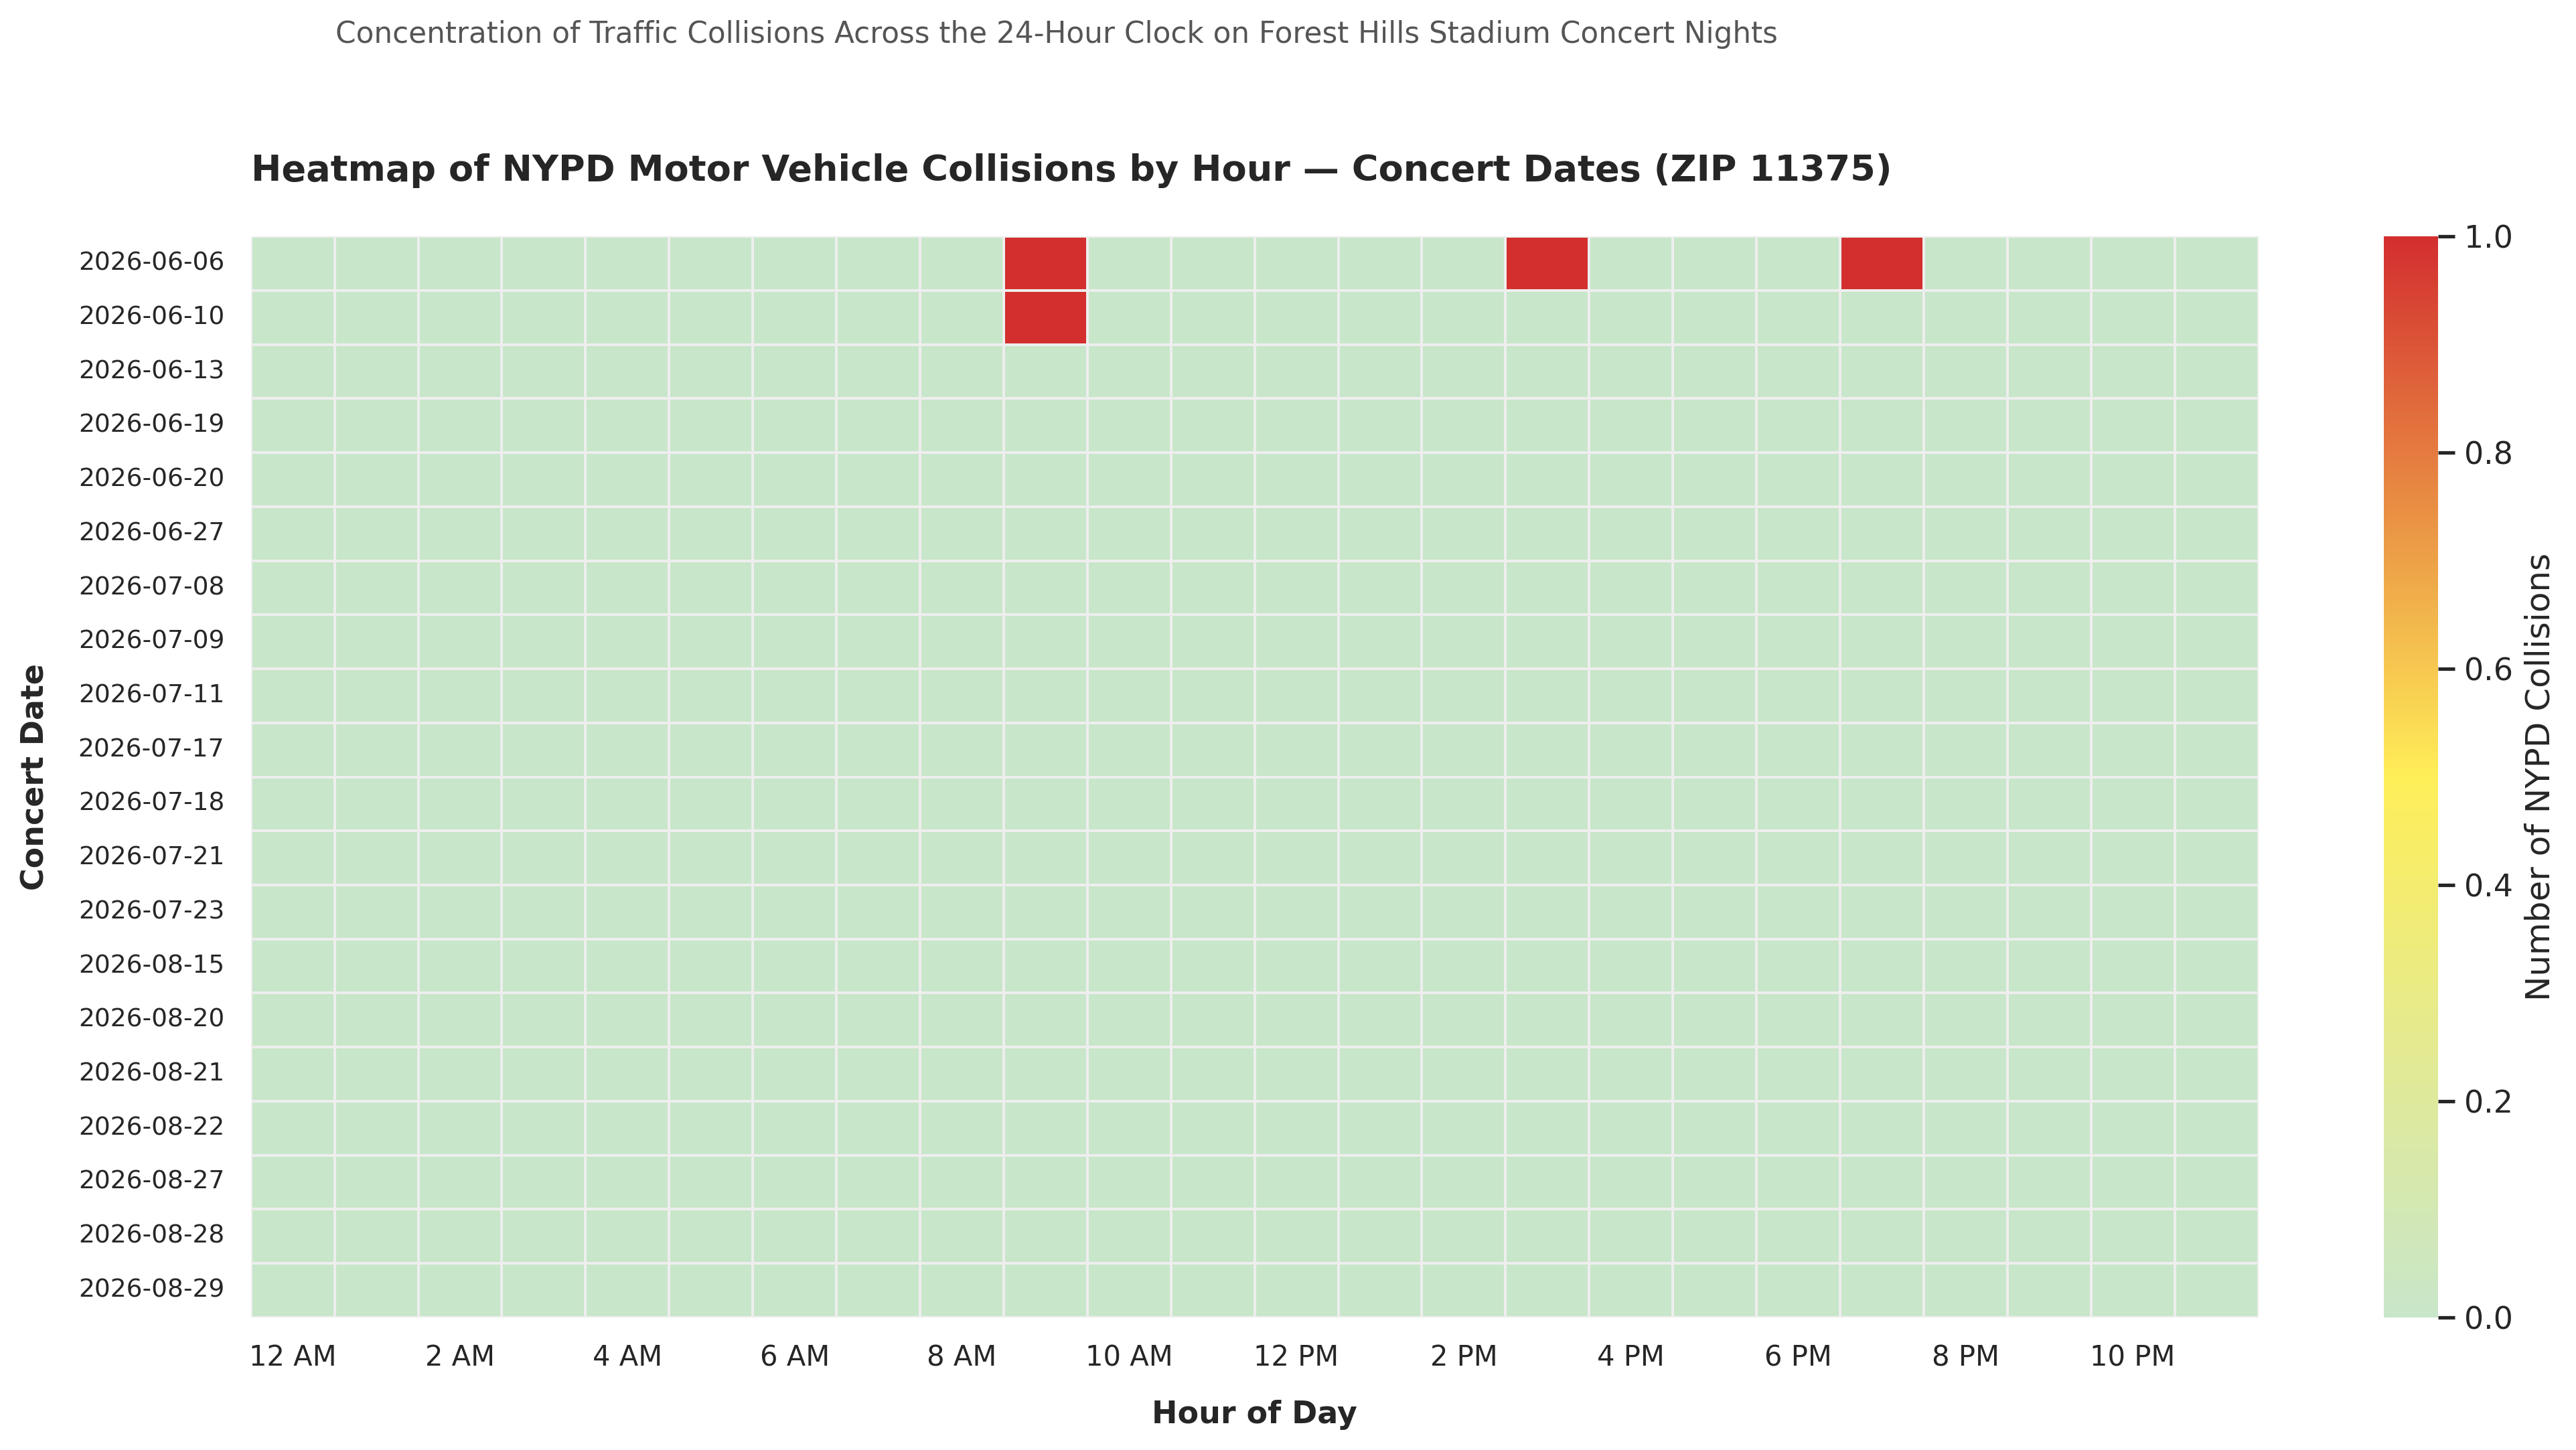

In [ ]:
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

# ==========================================
# 1. FETCH NYPD COLLISIONS FROM NYC OPEN DATA API
# ==========================================
# Socrata endpoint for NYPD Motor Vehicle Collisions
url = "https://data.cityofnewyork.us/resource/h9gi-nx95.json"

# Query for June 1, 2026 through August 31, 2026 in ZIP code 11375
where_clause = "zip_code='11375' AND crash_date >= '2026-06-01T00:00:00' AND crash_date <= '2026-08-31T23:59:59'"
params = {
    "$where": where_clause,
    "$limit": 50000,
    "$select": "collision_id, crash_date, crash_time, zip_code, latitude, longitude, number_of_persons_injured"
}

print("Fetching NYPD collision data from NYC Open Data API for ZIP 11375...")
response = requests.get(url, params=params)
data = response.json()

if not data:
    print("No collision records returned for the specified filters.")
else:
    df_crashes = pd.DataFrame(data)

    # Parse timestamps and extract date string and hour
    crash_dt = pd.to_datetime(df_crashes['crash_date'])
    df_crashes['date_str'] = crash_dt.dt.date.astype(str)

    # Extract hour from crash_time (format usually 'HH:MM')
    df_crashes['hour'] = pd.to_datetime(df_crashes['crash_time'], format='%H:%M', errors='coerce').dt.hour

    # Official 2026 Concert Dates for Forest Hills Stadium
    CONCERT_DATES = [
        # June 2026
        "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
        "2026-06-20", "2026-06-27",
        # July 2026
        "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
        "2026-07-18", "2026-07-21", "2026-07-23",
        # August 2026
        "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
        "2026-08-27", "2026-08-28", "2026-08-29"
    ]
    concert_set = set(CONCERT_DATES)

    # Filter strictly for concert days
    concert_crashes = df_crashes[df_crashes['date_str'].isin(concert_set)].copy()

    # Aggregate collision counts by Concert Date and Hour
    heatmap_data = concert_crashes.groupby(['date_str', 'hour']).size().reset_index(name='crash_count')

    # Create pivot table: Rows = Concert Dates, Columns = Hours (0-23)
    pivot_df = heatmap_data.pivot(index='date_str', columns='hour', values='crash_count').fillna(0)

    # Ensure all 24 hours (0-23) are present as columns
    for h in range(24):
        if h not in pivot_df.columns:
            pivot_df[h] = 0
    pivot_df = pivot_df[sorted(pivot_df.columns)]

    # Ensure all concert dates are present as rows (even if 0 crashes)
    all_concert_dates_sorted = sorted(list(concert_set))
    pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

    # ==========================================
    # 2. PLOT HEATMAP (Light Green for Low, Red for High)
    # ==========================================
    plt.figure(figsize=(14, 8), dpi=300)
    sns.set_theme(style="white")

    # Custom colormap: Light Green -> Soft Yellow -> Dark Red
    custom_cmap = LinearSegmentedColormap.from_list(
        "lightgreen_yellow_red",
        ["#C8E6C9", "#FFEE58", "#D32F2F"]
    )

    ax = sns.heatmap(
        pivot_df,
        cmap=custom_cmap,
        linewidths=0.5,
        linecolor='#EEEEEE',
        cbar_kws={'label': 'Number of NYPD Collisions'}
    )

    plt.title("Heatmap of NYPD Motor Vehicle Collisions by Hour — Concert Dates (ZIP 11375)", fontsize=13, fontweight='bold', pad=20, loc='left')
    plt.suptitle("Concentration of Traffic Collisions Across the 24-Hour Clock on Forest Hills Stadium Concert Nights", fontsize=10.5, color='#555555', x=0.125, y=0.93, ha='left')

    plt.xlabel("Hour of Day", fontsize=11, fontweight='semibold', labelpad=10)
    plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=10)

    hour_labels = ['12 AM', '2 AM', '4 AM', '6 AM', '8 AM', '10 AM', '12 PM',
                   '2 PM', '4 PM', '6 PM', '8 PM', '10 PM']
    plt.xticks(ticks=[i + 0.5 for i in range(0, 24, 2)], labels=hour_labels, rotation=0, fontsize=10)
    plt.yticks(fontsize=9, rotation=0)

    plt.tight_layout(rect=[0, 0.03, 1, 0.91])
    plt.show()

Processing June 2026 outbound fares to Outside of NYC...
Processing July 2026 outbound fares to Outside of NYC...
Processing August 2026 outbound fares to Outside of NYC...


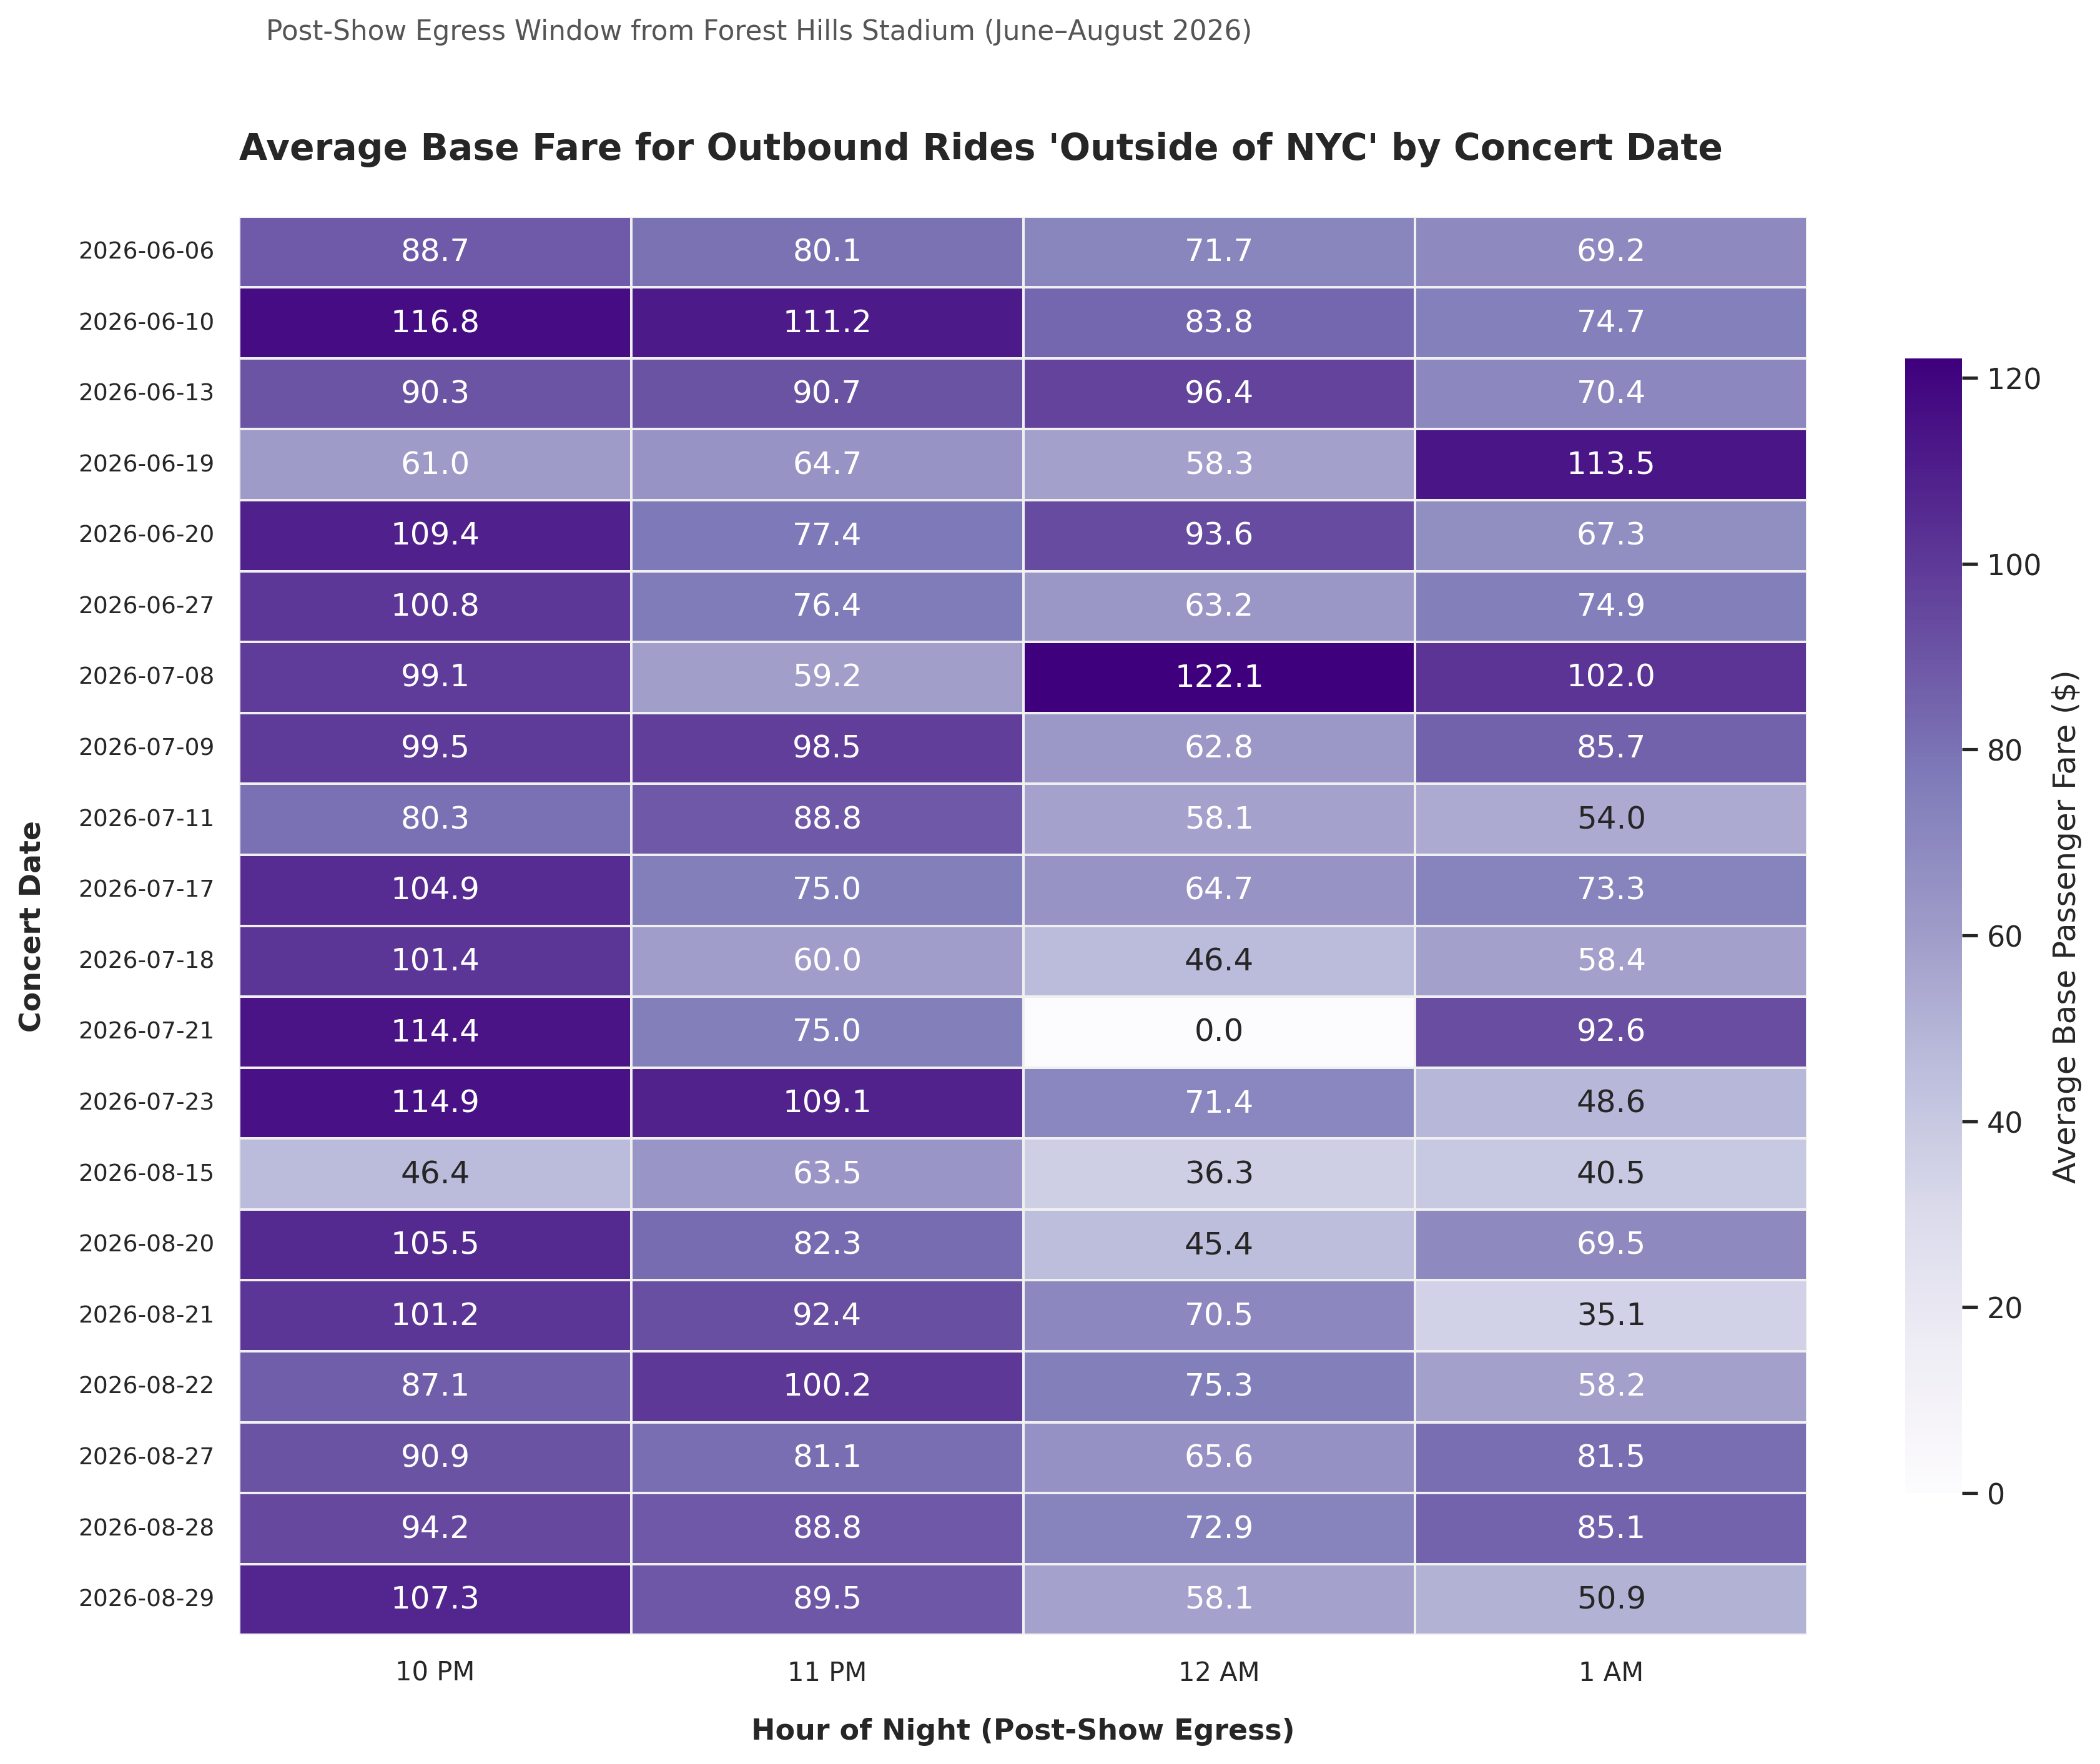


Success! Outbound average fare heatmap saved to 'forest_hills_outside_nyc_avg_fare_heatmap.png'.


In [5]:
import os
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CONFIGURATION & PARAMETERS
# ==========================================
FHV_FILES = {
    "June": "fhvhv_tripdata_2026-06.parquet",
    "July": "fhvhv_tripdata_2026-07.parquet",
    "August": "fhvhv_tripdata_2026-08.parquet"
}

# Official 2026 Concert Dates at Forest Hills Stadium (Total = 20 Concert Days)
CONCERT_DATES = [
    # June 2026
    "2026-06-06", "2026-06-10", "2026-06-13", "2026-06-19",
    "2026-06-20", "2026-06-27",
    # July 2026
    "2026-07-08", "2026-07-09", "2026-07-11", "2026-07-17",
    "2026-07-18", "2026-07-21", "2026-07-23",
    # August 2026
    "2026-08-15", "2026-08-20", "2026-08-21", "2026-08-22",
    "2026-08-27", "2026-08-28", "2026-08-29"
]
concert_set = set(CONCERT_DATES)
VENUE_ZONE_ID = 95   # Forest Hills Stadium Taxi Zone ID
OUTSIDE_NYC_ID = 265 # TLC Designated Zone ID for "Outside of NYC"

# ==========================================
# 2. DATA PROCESSING & OUTBOUND FARE EXTRACTION
# ==========================================
outbound_records = []

for month, file_path in FHV_FILES.items():
    if not os.path.exists(file_path):
        print(f"Warning: {file_path} not found. Skipping {month}...")
        continue

    print(f"Processing {month} 2026 outbound fares to Outside of NYC...")
    columns = ['pickup_datetime', 'dropoff_datetime', 'PULocationID', 'DOLocationID', 'base_passenger_fare']
    df = pd.read_parquet(file_path, columns=columns)

    # Filter strictly for pickups at Forest Hills Stadium (Zone 95) and drop-offs Outside of NYC (Zone 265)
    df = df[(df['PULocationID'] == VENUE_ZONE_ID) & (df['DOLocationID'] == OUTSIDE_NYC_ID)].copy()

    pickup_dt = pd.to_datetime(df['pickup_datetime'])
    df['pickup_hour'] = pickup_dt.dt.hour

    # Event date adjustment for post-midnight egress (trips up to 4 AM belong to concert night)
    event_dates = pickup_dt.dt.date.copy()
    early_morning_mask = df['pickup_hour'] < 4
    event_dates[early_morning_mask] = (pickup_dt[early_morning_mask] - pd.Timedelta(days=1)).dt.date
    df['event_date_str'] = event_dates.astype(str)

    is_concert = df['event_date_str'].isin(concert_set)

    # Post-show egress window: 22:00 (10 PM) to 01:59 (2 AM)
    post_show_window = df['pickup_hour'].isin([22, 23, 0, 1])

    outbound_records.append(df[is_concert & post_show_window][['event_date_str', 'pickup_hour', 'base_passenger_fare']])

if not outbound_records:
    raise ValueError("No valid outbound concert trip data processed for Outside of NYC.")

outbound_df = pd.concat(outbound_records, ignore_index=True)

# Adjust hours for sequential plotting (treat 0 and 1 as 24 and 25)
outbound_df['plot_hour'] = outbound_df['pickup_hour'].apply(lambda h: h + 24 if h < 4 else h)

# ==========================================
# 3. AGGREGATION & PIVOT TABLE CREATION
# ==========================================
# Calculate average (mean) base passenger fare by concert date and plot hour
fare_agg = outbound_df.groupby(['event_date_str', 'plot_hour'])['base_passenger_fare'].mean().reset_index(name='mean_fare')

pivot_df = fare_agg.pivot(index='event_date_str', columns='plot_hour', values='mean_fare').fillna(0)

# Ensure all concert dates are present as rows and all plot hours as columns
all_concert_dates_sorted = sorted(list(concert_set))
pivot_df = pivot_df.reindex(all_concert_dates_sorted, fill_value=0)

expected_hours = [22, 23, 24, 25]
for h in expected_hours:
    if h not in pivot_df.columns:
        pivot_df[h] = 0
pivot_df = pivot_df[expected_hours]

# ==========================================
# 4. PROFESSIONAL HEATMAP VISUALIZATION
# ==========================================
hour_labels = {
    22: '10 PM', 23: '11 PM', 24: '12 AM', 25: '1 AM'
}
pivot_df = pivot_df.rename(columns=hour_labels)

sns.set_theme(style="white", font="sans-serif")
plt.figure(figsize=(12, 10), dpi=300)

ax = sns.heatmap(
    pivot_df,
    cmap="Purples",  # Purple palette for fares
    annot=True,      # Show average fare amount values in cells
    fmt=".1f",       # Format as float ($XX.X)
    linewidths=0.5,
    linecolor='#f0f0f0',
    cbar_kws={'label': 'Average Base Passenger Fare ($)', 'shrink': 0.8},
    vmin=0
)

plt.title("Average Base Fare for Outbound Rides 'Outside of NYC' by Concert Date",
          fontsize=14, fontweight='bold', pad=22, loc='left')
plt.suptitle("Post-Show Egress Window from Forest Hills Stadium (June–August 2026)",
             fontsize=10.5, color='#555555', x=0.125, y=0.94, ha='left')

plt.xlabel("Hour of Night (Post-Show Egress)", fontsize=11, fontweight='semibold', labelpad=12)
plt.ylabel("Concert Date", fontsize=11, fontweight='semibold', labelpad=12)

plt.xticks(rotation=0, fontsize=10)
plt.yticks(fontsize=9)

plt.tight_layout(rect=[0, 0, 1, 0.93])

output_filename = "forest_hills_outside_nyc_avg_fare_heatmap.png"
plt.savefig(output_filename, bbox_inches='tight')
plt.show()
print(f"\nSuccess! Outbound average fare heatmap saved to '{output_filename}'.")